# Final model improvements: Human or AI?

A reproducible, non-pretrained experiment notebook. All models, token vocabularies and generative language models train from the supplied data. The fixed 2,000-row holdout is excluded from new selection; historical inspection of that holdout remains a limitation. Development cross-validation, held-out domains and formatting sensitivity determine selection, followed by one frozen holdout comparison and full-data refit.

Run every cell from a fresh Python kernel, or from this directory:
```powershell
jupyter nbconvert --to notebook --execute final_model_improvements.ipynb --inplace --ExecutePreprocessor.timeout=-1
```
Dependencies: numpy, pandas, scipy, scikit-learn, lightgbm, catboost, xgboost, PyYAML, joblib, matplotlib, nbformat and nbclient. Configuration lives in `models/final_model_improvements.yaml`, `final_nb_logreg.yaml`, and `final_ngram_lm.yaml`; historical YAMLs supply baseline settings. CPU is the default. `PLUM_MODE=smoke` selects a small check; smoke never writes the final CSV. Optional caches can be removed and are unnecessary for first execution.

Test text is used only for final inference and descriptive diagnostics: test-vocabulary adaptation and test pseudo-labeling are disabled. No pretrained downloads, external labeling, ID features or Kaggle API calls. All writes stay inside this submission. Existing notebooks/report/data are preserved.

The previous v3 headline OOF score is not a clean estimate of its complete pipeline: label-derived reference state and globally OOF language-model features crossed later evaluation boundaries. This notebook records fresh measurements rather than importing saved scores.

In [1]:
import os, sys, re, math, zlib, json, time, copy, hashlib, textwrap
from pathlib import Path
from collections import Counter
from functools import lru_cache, partial
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import yaml, joblib
from scipy.sparse import hstack, vstack, csr_matrix
from scipy.special import expit, logit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, ParameterSampler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from threadpoolctl import threadpool_limits
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_STARTED = time.time()
roots = set()
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    for candidate in [parent, parent / 'submissions' / 'plum']:
        if (candidate / 'models/final_model_improvements.yaml').is_file():
            roots.add(candidate.resolve())
assert len(roots) == 1, f'Expected one submission root, found {roots}'
SUBMISSION_DIR = roots.pop()
def local_path(relative):
    path = (SUBMISSION_DIR / relative).resolve()
    assert path.is_relative_to(SUBMISSION_DIR), f'Output outside submission: {path}'
    return path

def read_yaml(relative):
    with local_path(relative).open(encoding='utf-8') as f:
        return yaml.safe_load(f)

cfg = read_yaml('models/final_model_improvements.yaml')
MODE = os.environ.get('PLUM_MODE', cfg['runtime']['mode'])
assert MODE in ['full', 'smoke']
assert cfg['runtime']['device'] == 'cpu', 'This verified notebook uses CPU. GPU needs a separately validated configuration.'
assert not cfg['semi_supervised']['test_vocabulary'] and not cfg['semi_supervised']['test_pseudo_labels']
SEED = cfg['validation']['seed']
THREADS = cfg['runtime']['threads']
threadpool_limits(limits=THREADS)
np.random.seed(SEED)
ART = local_path(cfg['paths']['artifacts'])
if MODE == 'smoke': ART = ART / 'smoke'
ART.mkdir(parents=True, exist_ok=True)
CACHE = ART / 'cache'
CACHE.mkdir(exist_ok=True)
base0, base2, base3, nb_cfg, lm_cfg = [read_yaml(cfg['baseline_sources'][k]) for k in ['v0','v2','v3','nb','lm']]
VERSIONS = {p: metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','lightgbm','catboost','xgboost','PyYAML','joblib']}
notebook_path = local_path('final_model_improvements.ipynb')
IMPLEMENTATION_HASH = hashlib.sha256(''.join(c['source'] if isinstance(c['source'],str) else ''.join(c['source']) for c in json.loads(notebook_path.read_text(encoding='utf-8'))['cells'] if c['cell_type']=='code' and set(c.get('metadata',{}).get('tags',[])) & {'setup','feature-definitions','model-definitions','test-definitions'}).encode()).hexdigest()
ENSEMBLE_HASH = hashlib.sha256(''.join(c['source'] if isinstance(c['source'],str) else ''.join(c['source']) for c in json.loads(notebook_path.read_text(encoding='utf-8'))['cells'] if 'ensemble' in c.get('metadata',{}).get('tags',[])).encode()).hexdigest()
CONFIG_HASH = joblib.hash((cfg,base0,base2,base3,nb_cfg,lm_cfg,MODE,VERSIONS,IMPLEMENTATION_HASH))

def save_json(name, obj):
    (ART / name).write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)),encoding='utf-8')

def progress(message):
    line = f'[{(time.time()-RUN_STARTED)/60:.1f} min] {message}'
    print(line, flush=True)
    with (ART/'progress.log').open('a',encoding='utf-8') as f: f.write(line+'\n')

print('Submission:',SUBMISSION_DIR,'Mode:',MODE,'Threads:',THREADS)
display(pd.Series(VERSIONS,name='version').to_frame())


Submission: C:\Users\plum\Documents\Cornell Tech\human-or-ai-submissions\submissions\team-35\plum Mode: full Threads: 6


,version
numpy,2.4.6
pandas,2.3.3
scipy,1.18.0
scikit-learn,1.9.0
lightgbm,4.7.0
catboost,1.2.10
xgboost,3.4.1
PyYAML,6.0.3
joblib,1.5.3


## Data integrity and locked partitions
The starter set is a subset, never additional labeled data. Row order is preserved; ID is used only for alignment and fitting provenance.

In [2]:
data_candidates = []
if cfg['paths']['data_dir'] is not None:
    data_candidates = [(SUBMISSION_DIR / cfg['paths']['data_dir']).resolve()]
else:
    data_candidates = [p / 'data' for p in [SUBMISSION_DIR,*SUBMISSION_DIR.parents]]
required = ['train.csv','unlabeled.csv','test.csv','sample_submission.csv']
DATA_DIR = next((p for p in data_candidates if all((p/f).is_file() for f in required)),None)
if DATA_DIR is None: raise FileNotFoundError(f'Cannot find {required}; set paths.data_dir in YAML.')
frames = {name:pd.read_csv(DATA_DIR/name) for name in required}
train_all,unlabeled,test,sample = [frames[k] for k in required]
for name,frame in frames.items():
    assert frame['id'].is_unique and not frame.isna().any().any(), name
    if 'text' in frame: assert frame['text'].str.strip().ne('').all(),name
assert set(train_all.label.unique())=={0,1}
assert set(sample.id)==set(test.id) and len(sample)==len(test)
assert set(train_all.id).isdisjoint(test.id) and set(train_all.id).isdisjoint(unlabeled.id)
if (DATA_DIR/'train_starter_2000.csv').exists():
    starter = pd.read_csv(DATA_DIR/'train_starter_2000.csv')
    assert len(starter.merge(train_all,on=['id','text','label'],validate='one_to_one'))==len(starter)
DATA_HASHES = {f:hashlib.sha256((DATA_DIR/f).read_bytes()).hexdigest() for f in required}
development, official_holdout = train_test_split(train_all,test_size=cfg['validation']['holdout_size'],stratify=train_all.label,random_state=SEED)
development,official_holdout = development.reset_index(drop=True),official_holdout.reset_index(drop=True)
if MODE=='smoke':
    development = development.groupby('label',group_keys=False).sample(n=cfg['runtime']['smoke_rows']//2,random_state=SEED).reset_index(drop=True)
    official_holdout = official_holdout.groupby('label',group_keys=False).sample(n=cfg['runtime']['smoke_rows']//4,random_state=SEED).reset_index(drop=True)
    unlabeled=unlabeled.head(cfg['runtime']['smoke_rows']).copy()
assert set(development.id).isdisjoint(official_holdout.id)
pd.concat([development[['id']].assign(role='development'),official_holdout[['id']].assign(role='official_holdout')]).to_csv(ART/'split_ids.csv',index=False)
save_json('environment.json',{'python':sys.version,'versions':VERSIONS,'data':DATA_HASHES,'config_hash':CONFIG_HASH,'implementation_hash':IMPLEMENTATION_HASH,'seed':SEED,'mode':MODE,'test_fitting':False})
print('Read-only inputs:',DATA_DIR)
display(pd.DataFrame([{'split':k,'rows':len(f),'human':int((f.label==0).sum()) if 'label' in f else None,'AI':int((f.label==1).sum()) if 'label'in f else None} for k,f in [('development',development),('official_holdout',official_holdout),('unlabeled',unlabeled),('test',test)]]))


Read-only inputs: C:\Users\plum\Documents\Cornell Tech\human-or-ai-submissions\data


,split,rows,human,AI
0,development,8000,4000.0,4000.0
1,official_holdout,2000,1000.0,1000.0
2,unlabeled,3000,NaN,NaN
3,test,3000,NaN,NaN


## Feature definitions
The historical 90-column stateless extractor is embedded below for faithful baseline reproduction. Improved views use canonical text, corrected entropy and boundary counts, additional local statistics, and references fitted inside each training partition. These dictionaries are handwritten heuristics, not pretrained resources.

In [3]:
# 1. Core Stylometric, Information-Theoretic Compression & Dual Interpolated Language Model Feature Extractors
STOPWORDS = {
    'the','be','to','of','and','a','in','that','have','i','it','for','not','on','with',
    'he','as','you','do','at','this','but','his','by','from','they','we','say','her',
    'she','or','an','will','my','one','all','would','there','their','what','so','up',
    'out','if','about','who','get','which','go','me','when','make','can','like','time',
    'no','just','him','know','take','people','into','year','your','good','some','could',
    'them','see','other','than','then','now','look','only','come','its','over','think',
    'also','back','after','use','two','how','our','work','first','well','way','even',
    'new','want','because','any','these','give','day','most','us','is','are','was','were',
    'been','has','had','did','does','am','may','might','must','shall','should','ought',
    'need','dare','used'
}
PRONOUNS_1P = {'i','me','my','mine','myself','we','us','our','ours','ourselves'}
PRONOUNS_2P = {'you','your','yours','yourself','yourselves'}
PRONOUNS_3P = {'he','him','his','himself','she','her','hers','herself','it','its','itself','they','them','their','theirs','themselves'}
DET_ARTICLES = {'the','a','an','this','that','these','those','each','every','either','neither','some','any','no','much','many','few','several','all','both','half'}
PREPOSITIONS = {'of','in','to','for','with','on','at','from','by','about','as','into','like','through','after','over','between','out','against','during','without','before','under','around','among','within','upon','toward','towards','throughout','despite','beyond','across','behind','above','near','along','until','via'}
AUX_MODALS = {'be','am','is','are','was','were','been','being','have','has','had','having','do','does','did','will','would','shall','should','can','could','may','might','must','ought'}
CONJUNCTIONS = {'and','but','or','nor','for','yet','so','although','because','since','unless','while','whereas','whether','though','if','when','whenever','where','wherever','before','after','until','once'}
AI_TRANSITIONS = [
    'moreover','furthermore','in conclusion','delve','crucial','notably','additionally',
    'consequently','nevertheless','nonetheless','in summary','overall','importantly',
    'specifically','ultimately','vital','essential','significant','comprehensive',
    'robust','enhance','facilitate','utilize','leverage','paradigm','realm','tapestry',
    'testament','underscore','pivotal','intricate','foster','embark','nuanced','multifaceted'
]
HEDGING_WORDS = {
    'perhaps','maybe','possibly','probably','apparently','seemingly','arguably','roughly',
    'approximately','generally','typically','usually','often','sometimes','likely','unlikely',
    'suggest','suggests','indicate','indicates','appear','appears','seem','seems'
}
FUNCTION_VOCAB = (
    STOPWORDS | PRONOUNS_1P | PRONOUNS_2P | PRONOUNS_3P | DET_ARTICLES |
    PREPOSITIONS | AUX_MODALS | CONJUNCTIONS | HEDGING_WORDS |
    set(w for m in AI_TRANSITIONS for w in m.split())
)

SYL_RE_1 = re.compile(r'(?:[^laeiouy]es|ed|[^laeiouy]e)$')
SYL_RE_2 = re.compile(r'^y')
SYL_RE_3 = re.compile(r'[aeiouy]{1,2}')
TOKEN_RE = re.compile(r"[a-zA-Z]+(?:'[a-zA-Z]+)?")
TOKEN_PUNCT_RE = re.compile(r"[a-zA-Z]+(?:'[a-zA-Z]+)?|[0-9]+|[^\s\w]")
SENT_RE = re.compile(r'[.!?]+(?:\s+|$)')
CURLY_RE = re.compile(r'[\u201c\u201d\u2018\u2019]')
BULLET_RE = re.compile(r'(?:^|\n)\s*[-*•]\s')
HTML_BR_RE = re.compile(r'<br\s*/?>', re.IGNORECASE)

def strip_formatting(text: str) -> str:
    text = HTML_BR_RE.sub(' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def mask_content_words(text: str) -> str:
    text = HTML_BR_RE.sub(' \n ', text)
    tokens = TOKEN_PUNCT_RE.findall(text)
    out = []
    for tok in tokens:
        low = tok.lower()
        if low in FUNCTION_VOCAB:
            out.append(low)
        elif tok.isdigit():
            out.append('_NUM_')
        elif not tok[0].isalpha():
            out.append(tok)
        else:
            cap = 'T' if tok[0].isupper() else 'w'
            if len(low) >= 7:
                out.append(f'_{cap}_{low[-3:]}')
            elif len(low) >= 4:
                out.append(f'_{cap}_{low[-2:]}')
            else:
                out.append(f'_{cap}_s')
    return ' '.join(out)

def classify_observable_domain(text: str) -> str:
    t_low = text.lower()
    lines = [l.strip() for l in text.split('\n') if l.strip()]
    avg_line_words = len(text.split()) / max(len(lines), 1)
    if re.search(r'\b(ingredients|tablespoon|teaspoon|preheat|oven|chopped|cup|ounce)\b', t_low):
        return '1. Recipe / Cooking'
    if re.search(r'\b(we propose|this paper|state-of-the-art|neural network|convolutional|segmentation|algorithm|dataset|experiments|abstract|framework|method|model|learning)\b', t_low):
        return '2. Academic / ArXiv Abstract'
    if len(lines) >= 8 and avg_line_words < 10 and sum(1 for l in lines[:8] if l and l[0].isupper()) >= 6:
        return '3. Poetry / Verse / Lyrics'
    if re.search(r'\b(the novel|the book|the story|protagonist|narrates|published in|chapter)\b', t_low):
        return '4. Book / Novel Summary'
    if re.search(r'\b(the film|the movie|directed by|starring|box office|episode|season)\b', t_low) or '<br' in t_low:
        return '5. Film / TV / Review'
    if re.search(r'\b(born|politician|member of the|census-designated|is a|was a|located in)\b', t_low) and any(c.isdigit() for c in text[:150]):
        return '6. Encyclopedia / Wiki Bio'
    if re.search(r"\b(i am|i have|my|i'm|i was|reddit|tldr|edit:)\b", t_low):
        return '7. First-Person / Social'
    return '8. General / News / Other'

def count_syllables(word: str) -> int:
    if len(word) <= 3:
        return 1
    word = SYL_RE_1.sub('', word)
    word = SYL_RE_2.sub('', word)
    syls = SYL_RE_3.findall(word)
    return max(1, len(syls))

In [4]:
def extract_all_base_and_info_features(df: pd.DataFrame) -> pd.DataFrame:
    feats = []
    for text in df['text']:
        char_count = len(text)
        words_raw = text.split()
        word_count = max(len(words_raw), 1)
        alpha_tokens = TOKEN_RE.findall(text)
        lower_tokens = [w.lower() for w in alpha_tokens]
        n_alpha = max(len(lower_tokens), 1)

        sents = [s.strip() for s in SENT_RE.split(text) if s.strip()]
        sent_count = max(len(sents), 1)
        sent_lens = [len(s.split()) for s in sents] if sents else [word_count]
        avg_sent_len = float(np.mean(sent_lens))
        std_sent_len = float(np.std(sent_lens)) if len(sent_lens) > 1 else 0.0
        cv_sent_len = std_sent_len / max(avg_sent_len, 1.0)
        max_sent_len = float(np.max(sent_lens))
        min_sent_len = float(np.min(sent_lens))

        lines = text.split('\n')
        line_count = len(lines)
        non_empty_lines = [l.strip() for l in lines if l.strip()]
        non_empty_line_count = max(len(non_empty_lines), 1)
        newline_count = text.count('\n')
        double_newline_count = text.count('\n\n')
        has_double_newline = 1.0 if '\n\n' in text else 0.0
        has_single_newline_only = 1.0 if ('\n' in text and '\n\n' not in text) else 0.0
        single_newline_count = max(0, newline_count - 2 * double_newline_count)
        avg_line_len_words = word_count / non_empty_line_count

        vocab = {}
        for w in lower_tokens:
            vocab[w] = vocab.get(w, 0) + 1
        n_unique = len(vocab)
        ttr = n_unique / n_alpha
        root_ttr = n_unique / np.sqrt(n_alpha)
        log_ttr = np.log(max(n_unique, 1)) / max(np.log(max(n_alpha, 2)), 1e-5)
        hapax = sum(1 for v in vocab.values() if v == 1)
        dis_legomena = sum(1 for v in vocab.values() if v == 2)
        hapax_ratio = hapax / n_alpha
        hapax_vocab_ratio = hapax / max(n_unique, 1)
        dis_legomena_ratio = dis_legomena / n_alpha
        m1 = n_alpha
        m2 = sum(v * v for v in vocab.values())
        yules_k = 10000.0 * (m2 - m1) / max(m1 * m1, 1)

        word_lens = [len(w) for w in lower_tokens] if lower_tokens else [1]
        avg_word_len = float(np.mean(word_lens))
        std_word_len = float(np.std(word_lens))
        long_word_ratio = sum(1 for l in word_lens if l >= 7) / n_alpha
        short_word_ratio = sum(1 for l in word_lens if l <= 3) / n_alpha

        if len(lower_tokens) >= 3:
            bgs = [(lower_tokens[i], lower_tokens[i+1]) for i in range(len(lower_tokens)-1)]
            tgs = [(lower_tokens[i], lower_tokens[i+1], lower_tokens[i+2]) for i in range(len(lower_tokens)-2)]
            rep_2gram = 1.0 - len(set(bgs)) / len(bgs)
            rep_3gram = 1.0 - len(set(tgs)) / len(tgs)
        else:
            rep_2gram = 0.0
            rep_3gram = 0.0

        scale_c = 1000.0 / max(char_count, 1)
        comma_rate = text.count(',') * scale_c
        period_rate = text.count('.') * scale_c
        semicolon_rate = text.count(';') * scale_c
        colon_rate = text.count(':') * scale_c
        exclamation_rate = text.count('!') * scale_c
        question_rate = text.count('?') * scale_c
        hyphen_rate = text.count('-') * scale_c
        en_dash_rate = text.count('\u2013') * scale_c
        em_dash_rate = text.count('\u2014') * scale_c
        straight_quote_rate = text.count('"') * scale_c
        single_quote_rate = text.count("'") * scale_c
        curly_quote_rate = len(CURLY_RE.findall(text)) * scale_c
        paren_rate = (text.count('(') + text.count(')')) * scale_c
        slash_rate = text.count('/') * scale_c

        starts_with_quote = 1.0 if text.startswith('"') else 0.0
        ends_with_quote = 1.0 if text.endswith('"') else 0.0
        double_space_rate = text.count('  ') * scale_c
        has_bullet_list = 1.0 if BULLET_RE.search(text) else 0.0
        has_html_br = 1.0 if HTML_BR_RE.search(text) else 0.0

        upper_chars = sum(1 for c in text if c.isupper())
        digit_chars = sum(1 for c in text if c.isdigit())
        space_chars = sum(1 for c in text if c.isspace())
        punct_chars = sum(1 for c in text if not c.isalnum() and not c.isspace())
        upper_char_ratio = upper_chars / max(char_count, 1)
        digit_char_ratio = digit_chars / max(char_count, 1)
        space_char_ratio = space_chars / max(char_count, 1)
        punct_char_ratio = punct_chars / max(char_count, 1)
        title_word_ratio = sum(1 for w in alpha_tokens if w.istitle()) / n_alpha
        allcaps_word_ratio = sum(1 for w in alpha_tokens if w.isupper() and len(w) > 1) / n_alpha

        syl_counts = [count_syllables(w) for w in lower_tokens] if lower_tokens else [1]
        total_syls = sum(syl_counts)
        complex_words = sum(1 for s in syl_counts if s >= 3)
        avg_syl_per_word = total_syls / n_alpha
        complex_word_ratio = complex_words / n_alpha
        fk_grade = 0.39 * avg_sent_len + 11.8 * avg_syl_per_word - 15.59
        flesch_ease = 206.835 - 1.015 * avg_sent_len - 84.6 * avg_syl_per_word
        gunning_fog = 0.4 * (avg_sent_len + 100.0 * complex_word_ratio)
        ari = 4.71 * (char_count / word_count) + 0.5 * avg_sent_len - 21.43
        coleman_liau = 0.0588 * (sum(word_lens) / word_count * 100.0) - 0.296 * (sent_count / word_count * 100.0) - 15.8

        stop_ratio = sum(1 for w in lower_tokens if w in STOPWORDS) / n_alpha
        pron1_ratio = sum(1 for w in lower_tokens if w in PRONOUNS_1P) / n_alpha
        pron2_ratio = sum(1 for w in lower_tokens if w in PRONOUNS_2P) / n_alpha
        pron3_ratio = sum(1 for w in lower_tokens if w in PRONOUNS_3P) / n_alpha
        pron_total_ratio = pron1_ratio + pron2_ratio + pron3_ratio
        det_ratio = sum(1 for w in lower_tokens if w in DET_ARTICLES) / n_alpha
        prep_ratio = sum(1 for w in lower_tokens if w in PREPOSITIONS) / n_alpha
        aux_ratio = sum(1 for w in lower_tokens if w in AUX_MODALS) / n_alpha
        conj_ratio = sum(1 for w in lower_tokens if w in CONJUNCTIONS) / n_alpha

        adv_ly_ratio = sum(1 for w in lower_tokens if len(w) > 4 and w.endswith('ly')) / n_alpha
        verb_ing_ratio = sum(1 for w in lower_tokens if len(w) > 4 and w.endswith('ing')) / n_alpha
        verb_ed_ratio = sum(1 for w in lower_tokens if len(w) > 4 and w.endswith('ed')) / n_alpha
        noun_morph_ratio = sum(1 for w in lower_tokens if len(w) > 5 and w.endswith(('tion','sion','ment','ness','ity','ance','ence','ship','ism'))) / n_alpha
        adj_morph_ratio = sum(1 for w in lower_tokens if len(w) > 5 and w.endswith(('able','ible','al','ful','ic','ive','less','ous'))) / n_alpha
        contraction_rate = sum(1 for w in lower_tokens if "'" in w) / n_alpha

        text_lower = text.lower()
        ai_trans_count = sum(text_lower.count(marker) for marker in AI_TRANSITIONS)
        ai_trans_rate = ai_trans_count / word_count * 100.0
        hedge_rate = sum(1 for w in lower_tokens if w in HEDGING_WORDS) / n_alpha * 100.0

        # Information-Theoretic Compression & Entropy Features
        raw_bytes = text.encode('utf-8')
        n_bytes = max(len(raw_bytes), 1)
        comp_raw = len(zlib.compress(raw_bytes, level=9))
        comp_ratio_raw = comp_raw / n_bytes

        norm_text = strip_formatting(text)
        norm_bytes = norm_text.encode('utf-8')
        n_norm_bytes = max(len(norm_bytes), 1)
        comp_norm = len(zlib.compress(norm_bytes, level=9))
        comp_ratio_norm = comp_norm / n_norm_bytes

        mid = len(norm_bytes) // 2
        if mid > 20:
            c_h1 = len(zlib.compress(norm_bytes[:mid], level=9)) / mid
            c_h2 = len(zlib.compress(norm_bytes[mid:], level=9)) / max(len(norm_bytes) - mid, 1)
            c_inc_h2 = (comp_norm - len(zlib.compress(norm_bytes[:mid], level=9))) / max(len(norm_bytes) - mid, 1)
        else:
            c_h1 = c_h2 = c_inc_h2 = comp_ratio_norm

        c_counts = Counter(norm_text)
        n_c = max(len(norm_text), 1)
        char_entropy = -sum((v / n_c) * math.log2(v / n_c) for v in c_counts.values())
        if len(norm_text) >= 2:
            bg_counts = Counter(zip(norm_text[:-1], norm_text[1:]))
            n_bg = len(norm_text) - 1
            bg_entropy = -sum((v / n_bg) * math.log2(v / n_bg) for v in bg_counts.values())
            cond_char_entropy = bg_entropy - char_entropy
        else:
            cond_char_entropy = 0.0

        sents_norm = [s.strip() for s in SENT_RE.split(norm_text) if s.strip()]
        if len(sents_norm) >= 2:
            sent_sets = [set(re.findall(r'[a-zA-Z]+', s.lower())) for s in sents_norm]
            jaccards = [
                len(sent_sets[i] & sent_sets[i+1]) / max(len(sent_sets[i] | sent_sets[i+1]), 1)
                for i in range(len(sent_sets) - 1)
            ]
            adj_sent_jaccard_mean = float(np.mean(jaccards))
            adj_sent_jaccard_max = float(np.max(jaccards))
            sent_lens_n = [len(s.split()) for s in sents_norm]
            sent_len_diff_mean = float(np.mean(np.abs(np.diff(sent_lens_n)))) / max(np.mean(sent_lens_n), 1.0)
            first_words = [s.split()[0].lower() for s in sents_norm if s.split()]
            sent_starter_ttr = len(set(first_words)) / max(len(first_words), 1)
        else:
            adj_sent_jaccard_mean = 0.0
            adj_sent_jaccard_max = 0.0
            sent_len_diff_mean = 0.0
            sent_starter_ttr = 1.0

        if len(non_empty_lines) >= 2:
            line_lens = [len(l) for l in non_empty_lines]
            line_len_cv = float(np.std(line_lens)) / max(np.mean(line_lens), 1.0)
            line_end_punct_ratio = sum(1 for l in non_empty_lines if l[-1] in '.!?:;"\'\u201d\u2019)') / len(non_empty_lines)
            line_start_cap_ratio = sum(1 for l in non_empty_lines if l[0].isupper() or l[0] in '"-\u201c*•0123456789') / len(non_empty_lines)
        else:
            line_len_cv = 0.0
            line_end_punct_ratio = 1.0
            line_start_cap_ratio = 1.0

        feats.append({
            'word_count': word_count, 'char_count': char_count, 'sent_count': sent_count,
            'avg_sent_len': avg_sent_len, 'std_sent_len': std_sent_len, 'cv_sent_len': cv_sent_len,
            'max_sent_len': max_sent_len, 'min_sent_len': min_sent_len,
            'line_count': line_count, 'newline_count': newline_count,
            'double_newline_count': double_newline_count, 'single_newline_count': single_newline_count,
            'has_double_newline': has_double_newline, 'has_single_newline_only': has_single_newline_only,
            'avg_line_len_words': avg_line_len_words,
            'ttr': ttr, 'root_ttr': root_ttr, 'log_ttr': log_ttr,
            'hapax_ratio': hapax_ratio, 'hapax_vocab_ratio': hapax_vocab_ratio,
            'dis_legomena_ratio': dis_legomena_ratio, 'yules_k': yules_k,
            'avg_word_len': avg_word_len, 'std_word_len': std_word_len,
            'long_word_ratio': long_word_ratio, 'short_word_ratio': short_word_ratio,
            'rep_2gram': rep_2gram, 'rep_3gram': rep_3gram,
            'comma_rate': comma_rate, 'period_rate': period_rate,
            'semicolon_rate': semicolon_rate, 'colon_rate': colon_rate,
            'exclamation_rate': exclamation_rate, 'question_rate': question_rate,
            'hyphen_rate': hyphen_rate, 'en_dash_rate': en_dash_rate,
            'em_dash_rate': em_dash_rate, 'straight_quote_rate': straight_quote_rate,
            'single_quote_rate': single_quote_rate, 'curly_quote_rate': curly_quote_rate,
            'paren_rate': paren_rate, 'slash_rate': slash_rate,
            'starts_with_quote': starts_with_quote, 'ends_with_quote': ends_with_quote,
            'double_space_rate': double_space_rate, 'has_bullet_list': has_bullet_list,
            'has_html_br': has_html_br,
            'upper_char_ratio': upper_char_ratio, 'digit_char_ratio': digit_char_ratio,
            'space_char_ratio': space_char_ratio, 'punct_char_ratio': punct_char_ratio,
            'title_word_ratio': title_word_ratio, 'allcaps_word_ratio': allcaps_word_ratio,
            'avg_syl_per_word': avg_syl_per_word, 'complex_word_ratio': complex_word_ratio,
            'fk_grade': fk_grade, 'flesch_ease': flesch_ease,
            'gunning_fog': gunning_fog, 'ari': ari, 'coleman_liau': coleman_liau,
            'stop_ratio': stop_ratio, 'pron1_ratio': pron1_ratio,
            'pron2_ratio': pron2_ratio, 'pron3_ratio': pron3_ratio,
            'pron_total_ratio': pron_total_ratio, 'det_ratio': det_ratio,
            'prep_ratio': prep_ratio, 'aux_ratio': aux_ratio, 'conj_ratio': conj_ratio,
            'adv_ly_ratio': adv_ly_ratio, 'verb_ing_ratio': verb_ing_ratio,
            'verb_ed_ratio': verb_ed_ratio, 'noun_morph_ratio': noun_morph_ratio,
            'adj_morph_ratio': adj_morph_ratio, 'contraction_rate': contraction_rate,
            'ai_trans_rate': ai_trans_rate, 'hedge_rate': hedge_rate,
            'comp_ratio_raw': comp_ratio_raw, 'comp_ratio_norm': comp_ratio_norm,
            'comp_h2_minus_h1': c_h2 - c_h1, 'comp_inc_h2': c_inc_h2,
            'char_entropy': char_entropy, 'cond_char_entropy': cond_char_entropy,
            'adj_sent_jaccard_mean': adj_sent_jaccard_mean, 'adj_sent_jaccard_max': adj_sent_jaccard_max,
            'sent_len_diff_mean': sent_len_diff_mean, 'sent_starter_ttr': sent_starter_ttr,
            'line_len_cv': line_len_cv, 'line_end_punct_ratio': line_end_punct_ratio,
            'line_start_cap_ratio': line_start_cap_ratio
        })
    return pd.DataFrame(feats, index=df.index)

In [5]:
# Contract tests are intentionally defined before their implementations.
def test_contracts():
    toy = pd.DataFrame({'id':np.arange(12),'text':['Human ordinary sentence. More varied details!','AI artificial repeated words repeated words.']*6,'label':[0,1]*6,'group':np.arange(12)})
    pair = NGramPair(lm_cfg['word'], 'word').fit(toy)
    for context in [[],[pair.bos],[pair.bos,pair.bos],[pair.vocab.get('sentence',0),pair.vocab.get('ordinary',0)]]:
        ids=np.arange(pair.size,dtype=np.uint64)
        ids=ids[ids!=pair.bos]
        for model in pair.models:
            probs=pair.next_probabilities(model,context,ids)
            assert np.isclose(probs.sum(),1.0,atol=1e-10),(context,probs.sum())
    first=pair.score(toy.text).copy()
    pair.fit(toy)
    np.testing.assert_allclose(first,pair.score(toy.text),atol=0,rtol=0)
    assert pair.encode_tokens(['utterly_unseen_sentinel'])[0]==pair.unk
    a=np.array([[2.,0.],[0.,3.],[1.,0.],[0.,2.]],dtype=np.float32)
    nb=NBLogRatio(alpha=1.).fit(csr_matrix(a),np.array([0,1,0,1]))
    assert nb.r_[0]<0 and nb.r_[1]>0
    for raw in ['Roses fall\n\nAnd stars rise.','Hello<br />world. Test!','Ingredients:\n1 cup flour.','"A quoted\n\nsentence."']:
        f1=stateless_features(raw,True,True)
        f2=stateless_features(strip_formatting(raw),True,True)
        np.testing.assert_allclose(list(f1.values()),list(f2.values()),atol=1e-6)
    t,v=toy.iloc[:8].copy(),toy.iloc[8:].copy()
    state=ReferenceFeatures(canonical=True,shrink=20).fit(t)
    flipped=v.assign(label=1-v.label)
    pd.testing.assert_frame_equal(state.transform(v),state.transform(flipped))
    assert set(state.fit_ids_).isdisjoint(v.id)
    vec=TfidfVectorizer().fit(t.text)
    assert 'utterly_unseen_sentinel' not in vec.vocabulary_
    assert (vec.transform(['utterly_unseen_sentinel']).nnz)==0
    print('Passed: normalized LMs/BOS/UNK/reset, NB orientation, pure invariance, reference label isolation, inductive vocabulary.')


In [6]:
STRUCTURAL = ['double_newline_count','has_double_newline','has_single_newline_only','single_newline_count','newline_count','line_count','avg_line_len_words','starts_with_quote','ends_with_quote','double_space_rate','has_bullet_list','has_html_br','comp_ratio_raw','line_len_cv','line_end_punct_ratio','line_start_cap_ratio']
INFO = ['comp_ratio_raw','comp_ratio_norm','comp_h2_minus_h1','comp_inc_h2','char_entropy','cond_char_entropy','adj_sent_jaccard_mean','adj_sent_jaccard_max','sent_len_diff_mean','sent_starter_ttr','line_len_cv','line_end_punct_ratio','line_start_cap_ratio']
REDUCED_STRUCTURAL = ['double_newline_count','avg_line_len_words','line_len_cv','line_end_punct_ratio']
UNICODE_WORD_RE = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)?",re.UNICODE)

@lru_cache(maxsize=60000)
def stateless_features(text, canonical=False, improved=False):
    if canonical: text=strip_formatting(text)
    result=extract_all_base_and_info_features(pd.DataFrame({'text':[text]})).iloc[0].to_dict()
    if improved:
        words=UNICODE_WORD_RE.findall(text.lower().replace('’',"'"))
        n=max(len(words),1)
        result['ai_trans_rate']=sum(len(re.findall(r'(?<!\w)'+re.escape(m)+r'(?!\w)',text.lower())) for m in AI_TRANSITIONS)/n*100
        if len(text)>1:
            joint=Counter(zip(text[:-1],text[1:])); prev=Counter(text[:-1]); total=len(text)-1
            result['cond_char_entropy']=-sum(v/total*math.log2(v/prev[k[0]]) for k,v in joint.items())
        window=min(cfg['features']['mattr_window'],n)
        result['mattr_50']=float(np.mean([len(set(words[i:i+window]))/window for i in range(max(len(words)-window+1,1))]))
        lens=[len(UNICODE_WORD_RE.findall(s)) for s in SENT_RE.split(text) if s.strip()] or [0]
        result['sentence_median']=float(np.median(lens))
        result['sentence_iqr']=float(np.quantile(lens,.75)-np.quantile(lens,.25))
        gaps=np.diff([m.start() for m in re.finditer(r'[,.;:!?]',text)])
        result['punct_gap_cv']=float(np.std(gaps)/max(np.mean(gaps),1)) if len(gaps)>1 else 0.
        result['unicode_word_fraction']=sum(any(ord(c)>127 for c in w) for w in words)/n
        result['contraction_rate']=sum("'"in w for w in words)/n
    if canonical:
        result={k:v for k,v in result.items() if k not in STRUCTURAL}
    assert np.isfinite(list(result.values())).all()
    return result

class ReferenceFeatures:
    def __init__(self,canonical=False,improved=False,shrink=0,genre=True,info=True,structural='none',prune=False):
        self.canonical,self.improved,self.shrink=canonical,improved,shrink
        self.genre,self.info,self.structural,self.prune=genre,info,structural,prune
    def base(self,frame):
        return pd.DataFrame([stateless_features(t,self.canonical,self.improved) for t in frame.text],index=frame.index)
    def domains(self,frame):
        return frame.text.map(lambda t:classify_observable_domain(strip_formatting(t) if self.canonical else t)).to_numpy()
    def fit(self,frame):
        self.fit_ids_=frame.id.tolist()
        x=self.base(frame); human=x.loc[frame.label.to_numpy()==0]
        r=cfg['features']['reference_columns']; g=cfg['features']['genre_columns']; eps=cfg['features']['epsilon']
        self.median_=human[r].median();self.iqr_=(human[r].quantile(.75)-human[r].quantile(.25)).clip(lower=eps)
        self.mean_=human[g].mean();self.second_=(human[g]**2).mean()
        self.std_=np.sqrt((self.second_-self.mean_**2).clip(lower=0)).clip(lower=eps)
        self.domain_stats_={}; domains=self.domains(frame)
        for dom in np.unique(domains):
            h=x.loc[(domains==dom)&(frame.label.to_numpy()==0),g]; count=len(h)
            if count<cfg['features']['reference_min_support']:
                mean,second=self.mean_,self.second_
            else:
                lam=count/(count+self.shrink)
                mean=lam*h.mean()+(1-lam)*self.mean_
                second=lam*(h**2).mean()+(1-lam)*self.second_
            floor=np.maximum(self.std_*cfg['features']['std_floor_fraction'],eps)
            std=np.maximum(np.sqrt(np.maximum(second-mean**2,0)),floor)
            self.domain_stats_[dom]=(mean,std)
        self.columns_=None
        z=self.transform(frame)
        self.columns_=list(z.columns)
        if self.prune:
            usable=[c for c in self.columns_ if z[c].nunique()>1]
            corr=z[usable].corr().abs().fillna(0)
            keep=[]
            for c in usable:
                if not any(corr.loc[c,k]>=cfg['features']['correlation_threshold'] for k in keep):keep.append(c)
            self.columns_=keep
        return self
    def transform(self,frame):
        x=self.base(frame)
        if not self.canonical: x=x.drop(columns=[c for c in STRUCTURAL if c in x])
        if not self.info:x=x.drop(columns=[c for c in INFO if c in x])
        r=cfg['features']['reference_columns'];g=cfg['features']['genre_columns']
        for c in r:x[c+'_abs_dev']=np.abs(x[c]-self.median_[c])/self.iqr_[c]
        if self.genre:
            rows=[]
            for dom,(_,row) in zip(self.domains(frame),x.iterrows()):
                mean,std=self.domain_stats_.get(dom,(self.mean_,self.std_))
                rows.append(((row[g]-mean)/std).to_numpy(dtype=float))
            z=np.asarray(rows,dtype=float)
            for j,c in enumerate(g):x[c+'_genre_z']=z[:,j]
            x['genre_z_rms']=np.sqrt(np.mean(z*z,axis=1));x['genre_z_max']=np.abs(z).max(axis=1)
        if self.structural!='none':
            raw=pd.DataFrame([stateless_features(t,False,False) for t in frame.text],index=frame.index)
            columns=STRUCTURAL if self.structural=='full' else (STRUCTURAL[:12] if self.structural=='v2' else REDUCED_STRUCTURAL)
            for c in columns:x[c]=np.log1p(raw[c]) if c in ['double_newline_count','single_newline_count','newline_count','line_count'] else raw[c]
        if self.columns_ is not None:x=x[self.columns_]
        assert x.columns.is_unique and np.isfinite(x.to_numpy()).all()
        return x.astype(np.float32)

class NBLogRatio(TransformerMixin,BaseEstimator):
    def __init__(self,alpha=1.0):self.alpha=alpha
    def fit(self,X,y):
        y=np.asarray(y)
        p=self.alpha+np.asarray(X[y==1].sum(axis=0)).ravel()
        q=self.alpha+np.asarray(X[y==0].sum(axis=0)).ravel()
        self.r_=np.log(p/p.sum())-np.log(q/q.sum())
        return self
    def transform(self,X):return X.multiply(self.r_).tocsr()


In [7]:
def sorted_counts(values):
    return np.unique(values,return_counts=True)

def lookup(table,values):
    keys,counts=table
    indices=np.searchsorted(keys,values)
    clipped=np.minimum(indices,len(keys)-1)
    return np.where((indices<len(keys))&(keys[clipped]==values),counts[clipped],0).astype(float)

class NGramPair:
    # Integer-coded sorted counts avoid millions of Python tuple objects.
    def __init__(self,settings,kind='word'):
        self.settings=copy.deepcopy(settings);self.kind=kind
        self.order=settings['order'];self.alpha=settings['alpha']
    def tokens(self,text):
        text=strip_formatting(text)
        return list(text) if self.kind=='char' else [t.lower() for t in TOKEN_PUNCT_RE.findall(text)]
    def encode_tokens(self,tokens):
        return np.asarray([self.vocab.get(t,self.unk) for t in tokens],dtype=np.uint64)
    def event_codes(self,encoded,order):
        seq=np.concatenate([np.full(self.order-1,self.bos,dtype=np.uint64),encoded,np.array([self.eos],dtype=np.uint64)])
        size=len(encoded)+1; start=self.order-1
        codes=np.zeros(size,dtype=np.uint64)
        for lag in range(order-1,-1,-1):codes=codes*self.size+seq[start-lag:start-lag+size]
        return codes
    def fit(self,frame):
        self.fit_ids_=frame.id.tolist()
        tokenized=[self.tokens(t) for t in frame.text]
        counts=Counter(t for seq in tokenized for t in seq)
        vocabulary=sorted(t for t,c in counts.items() if c>=self.settings['min_count'] and t not in ['<UNK>','<EOS>','<BOS>'])
        self.unk,self.eos,self.bos=0,1,2
        self.vocab={t:i+3 for i,t in enumerate(vocabulary)}
        self.size=len(vocabulary)+3
        assert self.size**self.order < 2**64,'Ngram encoding overflow: reduce vocabulary or order'
        encoded=[self.encode_tokens(s) for s in tokenized]
        y=frame.label.to_numpy();self.models=[]
        for label in [0,1]:
            chosen=[s for s,c in zip(encoded,y) if c==label]
            assert chosen,'Both classes required for class-conditional LMs'
            model={'orders':{},'contexts':{}}
            for order in range(1,self.order+1):
                codes=np.concatenate([self.event_codes(s,order) for s in chosen])
                table=sorted_counts(codes);model['orders'][order]=table
                if order>1:model['contexts'][order]=sorted_counts(codes//self.size)
            model['total']=int(model['orders'][1][1].sum())
            self.models.append(model)
        return self
    def probabilities(self,model,encoded):
        uni=self.event_codes(encoded,1)
        p=(lookup(model['orders'][1],uni)+self.alpha)/(model['total']+self.alpha*(self.size-1))
        outputs=[np.log(p)]
        for order in range(2,self.order+1):
            code=self.event_codes(encoded,order)
            den=lookup(model['contexts'][order],code//self.size)
            count=lookup(model['orders'][order],code)
            mix=self.settings['interpolation'][order-2]
            p=np.where(den>0,mix*count/np.maximum(den,1)+(1-mix)*p,p)
            outputs.append(np.log(p))
        return outputs
    def next_probabilities(self,model,context,ids):
        p=(lookup(model['orders'][1],ids)+self.alpha)/(model['total']+self.alpha*(self.size-1))
        padded=[self.bos]*(self.order-1)+list(context)
        for order in range(2,self.order+1):
            prefix=0
            for i in padded[-(order-1):]:prefix=prefix*self.size+int(i)
            code=prefix*self.size+ids
            den=lookup(model['contexts'][order],np.full(len(ids),prefix,dtype=np.uint64))
            mix=self.settings['interpolation'][order-2]
            p=np.where(den>0,mix*lookup(model['orders'][order],code)/np.maximum(den,1)+(1-mix)*p,p)
        return p
    def score(self,texts):
        rows=[]
        for text in texts:
            encoded=self.encode_tokens(self.tokens(text));h,a=[self.probabilities(m,encoded) for m in self.models]
            llr=a[-1]-h[-1]
            if self.kind=='word':
                row={'lm_llr_uni_mean':np.mean(a[0]-h[0]),'lm_llr_bi_mean':np.mean(a[1]-h[1]),'lm_llr_tri_mean':np.mean(llr),'lm_llr_tri_std':np.std(llr),'lm_llr_tri_q75':np.quantile(llr,.75),'lm_llr_tri_q25':np.quantile(llr,.25),'lm_human_tri_ll_mean':np.mean(h[-1]),'lm_human_tri_ll_std':np.std(h[-1]),'lm_ai_tri_ll_mean':np.mean(a[-1]),'lm_ai_tri_ll_std':np.std(a[-1]),'lm_surprise_diff_std':np.std(a[-1])-np.std(h[-1])}
                if self.settings['extended']:
                    mid=max(len(llr)//2,1)
                    row.update(lm_oov_rate=np.mean(encoded==self.unk) if len(encoded) else 0,lm_llr_q10=np.quantile(llr,.1),lm_positive_fraction=np.mean(llr>0),lm_half_drift=np.mean(llr[mid:])-np.mean(llr[:mid]) if len(llr)>mid else 0)
            else:
                chunk=self.settings['chunk_size'];means=[np.mean(llr[i:i+chunk]) for i in range(0,len(llr),chunk)]
                row={'char_lm_llr_mean':np.mean(llr),'char_lm_llr_std':np.std(llr),'char_lm_llr_q10':np.quantile(llr,.1),'char_lm_llr_q90':np.quantile(llr,.9),'char_lm_human_mean':np.mean(h[-1]),'char_lm_ai_mean':np.mean(a[-1]),'char_lm_chunk_std':np.std(means)}
            rows.append(row)
        return pd.DataFrame(rows).astype(np.float32)


## Fold-local training engine
Stateless text features may be reused. Learned reference distributions, vocabulary/IDF, NB ratios, calibration and supervised LM features are fitted only inside their current training partition. Cache keys include true training labels and text, prediction text, model settings, library versions and implementation source. Prediction labels are never part of the fitting interface.

In [8]:
def fingerprint(frame,labels=False):
    columns=['id','text']+(['label'] if labels else [])
    if labels and 'group' in frame:columns+=['group']
    return joblib.hash(frame[columns].reset_index(drop=True))

PROVENANCE=set()
def provenance(train,target,role,settings):
    assert set(train.id).isdisjoint(target.id), f'Overlapping training/target IDs: {role}'
    key=joblib.hash((train.id.tolist(),target.id.tolist(),role,settings))
    if key not in PROVENANCE:
        record={'role':role,'train_ids':train.id.tolist(),'target_ids':target.id.tolist(),'settings':settings}
        PROVENANCE.add(key)
        folder=ART/'provenance';folder.mkdir(exist_ok=True)
        (folder/(key+'.json')).write_text(json.dumps(record,default=str),encoding='utf-8')
    return key

def cached_result(kind,key,compute):
    path=CACHE/(kind+'_'+joblib.hash((CONFIG_HASH,key))+'.joblib')
    if cfg['runtime']['cache'] and path.exists():return joblib.load(path)
    value=compute()
    if cfg['runtime']['cache']:
        joblib.dump(value,path,compress=3 if kind=='sparse_training' else 0)
        # Only files created in this notebook's dedicated cache are eligible for eviction.
        limit=cfg['runtime']['cache_limit_gb']*(1024**3)
        files=sorted(CACHE.glob('*.joblib'),key=lambda p:p.stat().st_mtime)
        total=sum(p.stat().st_size for p in files)
        for old in files:
            if total<=limit:break
            assert old.resolve().is_relative_to(local_path(cfg['paths']['artifacts']))
            size=old.stat().st_size
            old.unlink();total-=size
    return value

def make_folds(frame,n_splits=None,seed=None):
    n_splits=cfg['validation']['folds'] if n_splits is None else n_splits
    seed=SEED if seed is None else seed
    y=frame.label.to_numpy()
    groups=frame['group'].to_numpy() if 'group' in frame else frame.id.to_numpy()
    if len(np.unique(groups))<len(frame):
        folds=list(StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=seed).split(frame,y,groups))
    else:folds=list(StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=seed).split(frame,y))
    for t,v in folds:
        assert set(groups[t]).isdisjoint(groups[v])
        assert len(np.unique(y[t]))==2 and len(np.unique(y[v]))==2
    return folds

def transformed(frame,kind):
    out=frame[['id','text']].copy()
    if kind=='canonical':out['text']=out.text.map(strip_formatting)
    elif kind=='typography':out['text']=out.text.str.translate(str.maketrans({'’':"'",'‘':"'",'“':'"','”':'"','—':'-','–':'-'}))
    elif kind=='lowercase':out['text']=out.text.str.lower()
    elif kind.startswith('wrap'):
        width=int(kind[4:]);out['text']=out.text.map(lambda t:'\n'.join(textwrap.wrap(strip_formatting(t),width=width)))
    else:assert kind=='original'
    return out

def target_views(frame,kinds):
    # Repeated target IDs are intentional for aligned stress views; none overlap training IDs.
    return pd.concat([transformed(frame,k) for k in kinds],ignore_index=True)

def nested_lm_matrices(train,target,kind,settings,seed):
    key=(fingerprint(train,True),fingerprint(target),kind,settings,seed,lm_cfg['external_policy'])
    def compute():
        output=None;external=[]
        folds=make_folds(train,cfg['validation']['lm_inner_folds'],seed)
        for ti,vi in folds:
            t,v=train.iloc[ti],train.iloc[vi]
            provenance(t,v,'inner_'+kind+'_lm',settings)
            pair=NGramPair(settings,kind).fit(t)
            scores=pair.score(v.text)
            if output is None:output=pd.DataFrame(np.nan,index=np.arange(len(train)),columns=scores.columns)
            output.iloc[vi]=scores.to_numpy()
            if lm_cfg['external_policy']=='inner_mean':external.append(pair.score(target.text).to_numpy())
        if lm_cfg['external_policy']=='full':
            provenance(train,target,'external_'+kind+'_lm',settings)
            external=[NGramPair(settings,kind).fit(train).score(target.text).to_numpy()]
        assert output.notna().all().all()
        return output.astype(np.float32),pd.DataFrame(np.mean(external,axis=0),columns=output.columns).astype(np.float32)
    return cached_result('lm_features',key,compute)

def dense_matrices(train,target,spec,seed):
    settings={k:spec[k] for k in ['canonical','improved','shrink','genre','info','structural','prune','word_lm','char_lm']}
    key=(fingerprint(train,True),fingerprint(target),settings,seed)
    def compute():
        ref=ReferenceFeatures(**{k:settings[k] for k in ['canonical','improved','shrink','genre','info','structural','prune']}).fit(train)
        a,b=ref.transform(train).reset_index(drop=True),ref.transform(target).reset_index(drop=True)
        for kind in ['word','char']:
            if settings[kind+'_lm']:
                lm_settings=copy.deepcopy(lm_cfg[kind])
                if 'lm_settings' in spec:lm_settings.update(spec['lm_settings'].get(kind,{}))
                la,lb=nested_lm_matrices(train,target,kind,lm_settings,seed)
                a,b=pd.concat([a,la],axis=1),pd.concat([b,lb],axis=1)
        assert a.columns.is_unique and a.columns.equals(b.columns)
        return a,b
    # LM overrides are included explicitly; never reuse another smoothing configuration's features.
    return cached_result('dense',(key,spec.get('lm_settings',{})),compute)

# Cache only deterministic per-document analyzer output. No document frequencies,
# vocabulary selection, IDF, labels or fitted estimators enter this cache.
ANALYZER_BUILDERS={}
@lru_cache(maxsize=cfg['runtime']['analyzer_cache_entries'])
def cached_ngrams(key,text):
    return tuple(sys.intern(token) for token in ANALYZER_BUILDERS[key](text))

def cached_vectorizer(params):
    settings=vector_settings(params)
    analyzer_settings={k:v for k,v in settings.items() if k not in ['min_df','max_df','max_features','sublinear_tf','dtype','norm','use_idf','smooth_idf','binary']}
    key=joblib.hash(analyzer_settings)
    ANALYZER_BUILDERS.setdefault(key,TfidfVectorizer(**settings).build_analyzer())
    # The callable performs exactly the stock analyzer's tokenization/normalization.
    fitted_settings={k:v for k,v in settings.items() if k not in ['analyzer','ngram_range','token_pattern','lowercase','strip_accents','stop_words','preprocessor','tokenizer']}
    return TfidfVectorizer(**fitted_settings,analyzer=partial(cached_ngrams,key),token_pattern=None)

def vector_settings(settings):
    p=copy.deepcopy(settings)
    if 'ngram_range' in p:p['ngram_range']=tuple(p['ngram_range'])
    p['dtype']=np.float32
    return p

def sparse_matrices(train,target,spec,extra=None):
    key=(fingerprint(train,True),fingerprint(target),spec['views'],spec.get('vector_overrides',{}),spec.get('view_weights',{}),fingerprint(extra) if extra is not None else None)
    def compute():
        clean=train.text.map(strip_formatting);other=target.text.map(strip_formatting)
        a,b=[],[]
        for view in spec['views']:
            if view=='baseline':params=base0['vectorizers']['vec_w12'];tr,te=train.text,target.text
            else:
                key={'word':'word_tfidf','char_wb':'char_wb_tfidf','char':'char_cross_tfidf','mask':'mask_tfidf'}[view]
                params=copy.deepcopy(base3['vectorizers'][key]);tr,te=clean,other
                if view=='mask':
                    simple=spec.get('mask_simple',False)
                    def masking(s):
                        z=mask_content_words(s)
                        return re.sub(r'_[Tw]_[^ ]+', '_WORD_',z) if simple else z
                    tr,te=clean.map(masking),other.map(masking)
                params.update(spec.get('vector_overrides',{}).get(view,{}))
            corpus=tr
            if extra is not None:
                more=extra.text if view=='baseline' else extra.text.map(strip_formatting)
                if view=='mask':more=more.map(masking)
                corpus=pd.concat([tr,more],ignore_index=True)
            train_key=(fingerprint(train),view,params,spec.get('mask_simple',False),fingerprint(extra) if extra is not None else None)
            def fit_view():
                vectorizer=cached_vectorizer(params)
                matrix=vectorizer.fit_transform(corpus)
                return vectorizer,matrix[:len(tr)].tocsr()
            # Populate the stateless analyzer registry even when loading a fitted vectorizer.
            cached_vectorizer(params)
            vec,train_matrix=cached_result('sparse_training',train_key,fit_view)
            # Canonical/rewrapped views often repeat exactly; transform unique strings once.
            codes,unique_text=pd.factorize(te,sort=False)
            target_matrix=vec.transform(unique_text)[codes]
            weight=spec.get('view_weights',{}).get(view,1.)
            a.append(train_matrix*weight);b.append(target_matrix*weight)
        return hstack(a,format='csr',dtype=np.float32),hstack(b,format='csr',dtype=np.float32)
    return compute()

def model_params(family,params,seed):
    p=copy.deepcopy(params)
    if family=='lgb':p.update(n_jobs=THREADS,random_state=seed,verbosity=-1)
    elif family=='cat':p.update(task_type='CPU',thread_count=THREADS,random_seed=seed,allow_writing_files=False)
    elif family=='xgb':p.update(device='cpu',n_jobs=THREADS,random_state=seed,verbosity=0,tree_method='hist')
    return p

def fit_dense_estimator(family,params,seed):
    klass={'lgb':LGBMClassifier,'cat':CatBoostClassifier,'xgb':XGBClassifier}[family]
    return klass(**model_params(family,params,seed))

def fit_predict(train,target,spec,seed=SEED,use_cache=True):
    # Label columns are intentionally discarded before *any* target preprocessing.
    target=target[['id','text']].reset_index(drop=True)
    train=train.reset_index(drop=True)
    role=provenance(train,target,'branch',spec)
    key=(fingerprint(train,True),fingerprint(target),spec,seed)
    def compute():
        started=time.time();family=spec['family'];y=train.label.to_numpy()
        if family in ['lgb','cat','xgb']:
            a,b=dense_matrices(train,target,spec,seed)
            weights=np.ones(len(train))
            if spec.get('augmentation',0):
                rng=np.random.default_rng(seed)
                take=np.flatnonzero(rng.random(len(train))<cfg['augmentation']['fraction'])
                copy_frame=train.iloc[take].copy()
                copy_frame['text']=transformed(copy_frame,cfg['augmentation']['transform']).text.to_numpy()
                # Reuse the training reference state, not statistics from target or augmented labels.
                ref=ReferenceFeatures(**{k:spec[k] for k in ['canonical','improved','shrink','genre','info','structural','prune']}).fit(train)
                aug=ref.transform(copy_frame).reset_index(drop=True)
                # LM views are canonical and have unchanged scores for canonical augmentation.
                for c in a.columns:
                    if c not in aug:aug[c]=a.iloc[take][c].to_numpy()
                aug=aug[a.columns]
                weight=spec['augmentation'];weights[take]/=(1+weight)
                weights=np.r_[weights,np.full(len(take),weight/(1+weight))]
                a=pd.concat([a,aug],ignore_index=True);y=np.r_[y,y[take]]
            model=fit_dense_estimator(family,spec['params'],seed).fit(a,y,sample_weight=weights)
            p=model.predict_proba(b)[:,list(model.classes_).index(1)]
            train_probability=model.predict_proba(a.iloc[:len(train)])[:,list(model.classes_).index(1)]
            details={'features':list(a.columns),'params':model.get_params(),'n_features':a.shape[1]}
        elif family in ['lr','svc']:
            # Calibration wraps a *complete* sparse pipeline with its own fold-local vocabulary.
            if family=='svc':
                members=[];train_members=[]
                for ti,vi in make_folds(train,cfg['models']['calibration_folds'],seed):
                    inner=train.iloc[ti];cal=train.iloc[vi]
                    aa,bb=sparse_matrices(inner,pd.concat([cal[['id','text']],target,train[['id','text']]],ignore_index=True),spec)
                    svc=LinearSVC(C=spec['params']['C'],random_state=seed,max_iter=cfg['models']['svc_max_iter']).fit(aa,inner.label)
                    margins=svc.decision_function(bb)
                    calibrator=LogisticRegression(C=cfg['ensemble']['calibration_C'],max_iter=cfg['models']['lr_max_iter']).fit(margins[:len(cal)].reshape(-1,1),cal.label)
                    members.append(calibrator.predict_proba(margins[len(cal):len(cal)+len(target)].reshape(-1,1))[:,1])
                    train_members.append(calibrator.predict_proba(margins[len(cal)+len(target):].reshape(-1,1))[:,1])
                    provenance(inner,cal,'svc_calibration',spec)
                p=np.mean(members,axis=0);train_probability=np.mean(train_members,axis=0);details={'params':spec['params'],'n_features':aa.shape[1]}
            else:
                a,b=sparse_matrices(train,target,spec)
                model=LogisticRegression(**spec['params'],random_state=seed,solver=cfg['models']['lr_solver']).fit(a,y)
                p=model.predict_proba(b)[:,1];train_probability=model.predict_proba(a)[:,1];details={'params':model.get_params(),'n_features':a.shape[1]}
        elif family=='nb':
            params=vector_settings(spec['vectorizer'])
            vec=CountVectorizer(**params)
            a,b=vec.fit_transform(train.text.map(strip_formatting)),vec.transform(target.text.map(strip_formatting))
            ratio=NBLogRatio(spec['alpha']).fit(a,y)
            model=LogisticRegression(C=spec['C'],max_iter=nb_cfg['max_iter'],random_state=seed).fit(ratio.transform(a),y)
            p=model.predict_proba(ratio.transform(b))[:,1];train_probability=model.predict_proba(ratio.transform(a))[:,1];details={'params':model.get_params(),'n_features':a.shape[1]}
        elif family=='char_direct':
            pair=NGramPair(spec['lm_settings'],'char').fit(train)
            z=pair.score(target.text)
            p=expit(z.char_lm_llr_mean.to_numpy());train_probability=None;details={'params':spec['lm_settings'],'n_features':1}
        else:raise ValueError(family)
        assert len(p)==len(target) and np.isfinite(p).all() and np.all((p>=0)&(p<=1))
        return p,dict(details,seconds=time.time()-started,provenance=role,train_probability=train_probability)
    return cached_result('prediction',key,compute) if use_cache else compute()


In [9]:
def dense_spec(family='lgb',structural='none',legacy=True,word_lm=True,char_lm=False,**changes):
    key=family+('_struct' if structural!='none' else '_pure')
    spec={'family':family,'canonical':not legacy,'improved':not legacy,'shrink':0 if legacy else 20,'genre':True,'info':True,'structural':structural,'prune':False,'word_lm':word_lm,'char_lm':char_lm,'params':copy.deepcopy(base3['stage1_specialists'][key])}
    spec.update(changes);return spec

def sparse_spec(kind='lr',views=None,params=None):
    if views is None:views=['word','char_wb','char','mask']
    if params is None:
        key='svc_4v' if kind=='svc' else ('mask_lr' if views==['mask'] else 'lr_4v')
        params=copy.deepcopy(base3['stage1_specialists'][key]);params.pop('cv',None)
    return {'family':kind,'views':views,'params':params}

def historical_fusions(pred):
    b3=base3['stage1_blend'];n=b3['nofmt_weights'];s=b3['struct_weights'];f=b3['fusion_weights'];eps=cfg['ensemble']['clip']
    pure=(pred['lgb_pure']+pred['cat_pure']+pred['xgb_pure'])/3
    nofmt=n['lr_4v']*pred['lr_4v']+n['svc_4v']*pred['svc_4v']+n['mask_lr']*pred['mask_lr']+n['gbdt_pure']*pure
    struct=sum(s[k]*logit(np.clip(pred[k],eps,1-eps)) for k in s)
    v3=expit(f['nofmt']*logit(np.clip(nofmt,eps,1-eps))+f['struct']*struct)
    w=base2['blend_weights'];n2=w['nofmt'];f2=w['stage1_fusion']
    p2=sum(n2[k]*pred[k] for k in n2)
    v2=expit(f2['nofmt']*logit(np.clip(p2,eps,1-eps))+f2['struct']*logit(np.clip(pred['lgb_struct'],eps,1-eps)))
    return {'B2_v3_corrected':v3,'B1_v2_corrected':v2,'v3_pure_blend':nofmt}

def metrics(y,p):
    return {'auc':roc_auc_score(y,p),'brier':brier_score_loss(y,p),'logloss':log_loss(y,np.clip(p,cfg['ensemble']['clip'],1-cfg['ensemble']['clip']),labels=[0,1])}


In [10]:
test_contracts()
# Full prediction must be insensitive to validation labels, not only reference transforms.
toy=pd.DataFrame({'id':np.arange(40)+1000000,'text':['Ordinary human sentence with details. Another uneven thought!','Generated text repeated text repeated. Smooth conclusion.']*20,'label':[0,1]*20,'group':np.arange(40)})
t,v=toy.iloc[:30].copy(),toy.iloc[30:].copy()
spec=dense_spec(word_lm=False)
spec['params']=dict(spec['params'],n_estimators=8,min_child_samples=2,num_leaves=3)
p,_=fit_predict(t,v,spec,use_cache=False)
q,_=fit_predict(t,v.assign(label=1-v.label),spec,use_cache=False)
np.testing.assert_allclose(p,q,atol=0,rtol=0)
spec_pure=dense_spec(legacy=False,word_lm=False,genre=False)
spec_pure['params']=dict(spec_pure['params'],n_estimators=8,min_child_samples=2,num_leaves=3)
p,_=fit_predict(t,v,spec_pure,use_cache=False)
q,_=fit_predict(t,transformed(v,'canonical'),spec_pure,use_cache=False)
np.testing.assert_allclose(p,q,atol=1e-10,rtol=0)
probe=fit_dense_estimator('lgb',{'n_estimators':17,'num_leaves':7},SEED)
assert probe.get_params()['n_estimators']==17
progress('All feature, LM, leakage, pure-prediction and configuration contracts pass.')

# Stock and cached analyzers must produce the exact same vocabulary and numbers.
benchmark_rows=cfg['runtime']['analyzer_benchmark_rows']
benchmark_text=development.text.head(benchmark_rows).map(strip_formatting)
analyzer_benchmark=[]
for view in ['word_tfidf','char_cross_tfidf','mask_tfidf']:
    settings=copy.deepcopy(base3['vectorizers'][view])
    docs=benchmark_text.map(mask_content_words) if view=='mask_tfidf' else benchmark_text
    started=time.perf_counter();stock=TfidfVectorizer(**vector_settings(settings));expected=stock.fit_transform(docs);stock_time=time.perf_counter()-started
    started=time.perf_counter();fast=cached_vectorizer(settings);actual=fast.fit_transform(docs);cold_time=time.perf_counter()-started
    started=time.perf_counter();warm=cached_vectorizer(settings);again=warm.fit_transform(docs);warm_time=time.perf_counter()-started
    np.testing.assert_array_equal(stock.get_feature_names_out(),fast.get_feature_names_out())
    difference=expected-actual
    assert difference.nnz==0 or np.max(np.abs(difference.data))<=1e-6
    difference=expected-again
    assert difference.nnz==0 or np.max(np.abs(difference.data))<=1e-6
    # Callable pickling is exercised across saved training-vectorizer cache loads.
    path=CACHE/('analyzer_contract_'+view+'.joblib');joblib.dump(fast,path)
    restored=joblib.load(path)
    difference=restored.transform(docs)-actual
    assert difference.nnz==0 or np.max(np.abs(difference.data))<=1e-6
    path.unlink()
    analyzer_benchmark.append({'view':view,'rows':len(docs),'stock_seconds':stock_time,'cached_cold_seconds':cold_time,'cached_warm_seconds':warm_time})
pd.DataFrame(analyzer_benchmark).to_csv(ART/'analyzer_equivalence_benchmark.csv',index=False)
display(pd.DataFrame(analyzer_benchmark))

# Inductive prediction is row-wise: adding other query rows cannot change a prediction.
_extra_query=v[['id','text']].copy();_extra_query['id']+=10000000
_extra_query['text']+=' Different query content.'
_single,_=fit_predict(t,v,spec_pure,SEED,use_cache=False)
_batched,_=fit_predict(t,pd.concat([v[['id','text']],_extra_query],ignore_index=True),spec_pure,SEED,use_cache=False)
assert np.ptp(_single)>0
np.testing.assert_allclose(_single,_batched[:len(v)],atol=1e-10,rtol=0)


Passed: normalized LMs/BOS/UNK/reset, NB orientation, pure invariance, reference label isolation, inductive vocabulary.
[0.0 min] All feature, LM, leakage, pure-prediction and configuration contracts pass.


,view,rows,stock_seconds,cached_cold_seconds,cached_warm_seconds
0,word_tfidf,400,0.332776,0.364683,0.279855
1,char_cross_tfidf,400,0.862254,1.213753,0.625472
2,mask_tfidf,400,0.553867,0.647835,0.481716


## Duplicate audit and evaluation tasks
Near-duplicate groups are formed conservatively from text similarity using an audit vocabulary fitted on development only. The audit does not supply model features or labels. Official split membership is preserved; any overlap gets a separate purged sensitivity result.

In [11]:
audit_frames=[train_all[['id','text']],unlabeled[['id','text']]]
audit=pd.concat(audit_frames,ignore_index=True).drop_duplicates('id').reset_index(drop=True)
vec=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=cfg['validation']['duplicate_features'],sublinear_tf=True,dtype=np.float32)
vec.fit(development.text.map(strip_formatting))
X=vec.transform(audit.text.map(strip_formatting))
parent=np.arange(len(audit))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]];i=parent[i]
    return i
pairs=[];chunk=cfg['validation']['duplicate_chunk'];threshold=cfg['validation']['duplicate_threshold']
for start in range(0,len(audit),chunk):
    sim=(X[start:start+chunk]@X.T).tocoo()
    mask=(sim.data>=threshold)&(start+sim.row<sim.col)
    for i,j,value in zip(start+sim.row[mask],sim.col[mask],sim.data[mask]):
        parent[find(int(j))]=find(int(i));pairs.append((int(audit.id.iloc[i]),int(audit.id.iloc[j]),float(value)))
group_map={int(audit.id.iloc[i]):int(audit.id.iloc[find(i)]) for i in range(len(audit))}
for frame in [train_all,development,official_holdout,unlabeled]:
    frame['group']=frame.id.map(group_map).fillna(frame.id).astype(int)
    frame['heuristic_domain']=frame.text.map(classify_observable_domain)
train_all[['id','group']].to_csv(ART/'duplicate_groups.csv',index=False)
pd.DataFrame(pairs,columns=['id_a','id_b','cosine']).to_csv(ART/'duplicate_pairs.csv',index=False)
print('Near-duplicate pairs (development-fitted audit representation):',len(pairs))
for name,frame in [('development',development),('unlabeled',unlabeled),('holdout',official_holdout)]:
    print(name,'exact duplicates',frame.text.duplicated().sum(),'normalized',frame.text.map(lambda t:strip_formatting(t).lower()).duplicated().sum())
CV_FOLDS=make_folds(development)
SCREEN_FOLDS=make_folds(development,cfg['validation']['screen_folds'])
fold_ids=[]
for i,(ti,vi) in enumerate(CV_FOLDS):
    fold_ids.extend({'id':int(development.id.iloc[j]),'fold':i,'group':int(development.group.iloc[j])} for j in vi)
pd.DataFrame(fold_ids).to_csv(ART/'development_folds.csv',index=False)
OOD_TASKS=[]
for domains in cfg['validation']['ood_domains']:
    mask=development.heuristic_domain.isin(domains).to_numpy();ti,vi=np.flatnonzero(~mask),np.flatnonzero(mask)
    counts=development.iloc[vi].label.value_counts().reindex([0,1],fill_value=0)
    if counts.min()>=cfg['validation']['min_domain_class']:
        # Purge training siblings of held-out domain rows.
        held_groups=set(development.iloc[vi].group)
        ti=np.array([j for j in ti if development.group.iloc[j] not in held_groups],dtype=int)
        OOD_TASKS.append(('+'.join(d.split('.')[0] for d in domains),ti,vi))
    else:print('Insufficient OOD support:',domains,counts.to_dict())
save_json('ood_splits.json',[{'name':name,'train_ids':development.id.iloc[ti].tolist(),'target_ids':development.id.iloc[vi].tolist()} for name,ti,vi in OOD_TASKS])
del X,vec,audit
progress(f'Audit complete: {len(CV_FOLDS)} grouped CV folds, {len(OOD_TASKS)} supported OOD tasks.')


Near-duplicate pairs (development-fitted audit representation): 24


development exact duplicates 0 normalized 0
unlabeled exact duplicates 0 normalized 0
holdout exact duplicates 0 normalized 0


[0.4 min] Audit complete: 5 grouped CV folds, 5 supported OOD tasks.


In [12]:
assert cfg['models']['calibration_method']=='sigmoid', 'Only the documented sigmoid SVC calibration is implemented.'
EXPERIMENT_RECORDS=[]
EVALUATIONS={}
KINDS=cfg['validation']['stress']

def evaluate_spec(name,spec,folds=None,ood=True,stress=True,seed=SEED):
    if folds is None:folds=CV_FOLDS
    kinds=KINDS if stress else ['original']
    all_p={k:np.full(len(development),np.nan) for k in kinds};fold_scores=[];seconds=0
    for fold,(ti,vi) in enumerate(folds):
        t,v=development.iloc[ti],development.iloc[vi]
        p,info=fit_predict(t,target_views(v,kinds),spec,seed+fold)
        seconds+=info['seconds']
        for j,k in enumerate(kinds):all_p[k][vi]=p[j*len(v):(j+1)*len(v)]
        fold_scores.append(roc_auc_score(v.label,all_p['original'][vi]))
        progress(f'{name}: CV {fold+1}/{len(folds)} AUC {fold_scores[-1]:.5f}')
    valid=np.isfinite(all_p['original']);ys=development.label.to_numpy()
    record={'name':name,'cv_auc':roc_auc_score(ys[valid],all_p['original'][valid]),'fold_mean':float(np.mean(fold_scores)),'fold_sd':float(np.std(fold_scores)),'runtime_s':seconds,'n_features':info['n_features']}
    record.update({k+'_auc':roc_auc_score(ys[valid],p[valid]) for k,p in all_p.items()})
    record.update({'cv_'+k:v for k,v in metrics(ys[valid],all_p['original'][valid]).items() if k!='auc'})
    ood_predictions={}
    if ood:
        for task,ti,vi in OOD_TASKS:
            p,detail=fit_predict(development.iloc[ti],target_views(development.iloc[vi],kinds),spec,seed)
            ood_predictions[task]={k:p[j*len(vi):(j+1)*len(vi)] for j,k in enumerate(kinds)}
            record['ood_'+task]=roc_auc_score(ys[vi],ood_predictions[task]['original'])
            progress(f'{name}: OOD {task} AUC {record["ood_"+task]:.5f}')
    record['task_mean']=float(np.mean([record['cv_auc']]+[record['ood_'+task] for task in ood_predictions]))
    EVALUATIONS[name]={'spec':copy.deepcopy(spec),'cv':all_p,'ood':ood_predictions,'record':record}
    EXPERIMENT_RECORDS.append(record)
    pd.DataFrame(EXPERIMENT_RECORDS).to_csv(ART/'experiments.csv',index=False)
    pd.DataFrame({'id':development.id,'label':ys,**all_p}).to_csv(ART/(name+'_development_predictions.csv'),index=False)
    save_json(name+'_spec.json',spec)
    return record

BASE_SPECS={'B0_word_lr':sparse_spec(views=['baseline'],params=copy.deepcopy(base0['models']['model_a']['params'])),'lr_4v':sparse_spec(),'svc_4v':sparse_spec('svc'),'mask_lr':sparse_spec(views=['mask'])}
for family in ['lgb','cat','xgb']:
    for branch in ['pure','struct']:
        BASE_SPECS[family+'_'+branch]=dense_spec(family,'full' if branch=='struct' else 'none')
for branch in ['pure','struct']:
    spec=dense_spec('lgb','v2' if branch=='struct' else 'none',word_lm=False,info=False)
    spec['params']=copy.deepcopy(base2['specialists']['lgb_'+branch])
    BASE_SPECS['v2_lgb_'+branch]=spec
if MODE=='smoke':
    for s in BASE_SPECS.values():
        if s['family'] in ['lgb','xgb']:s['params']['n_estimators']=20
        if s['family']=='cat':s['params']['iterations']=20

for name,spec in BASE_SPECS.items():evaluate_spec(name,spec)

for fused in ['B1_v2_corrected','B2_v3_corrected','v3_pure_blend']:
    predictions={k:historical_fusions({name:EVALUATIONS['v2_'+name if fused=='B1_v2_corrected' and name.startswith('lgb_') else name]['cv'][k] for name in ['lr_4v','svc_4v','mask_lr','lgb_pure','lgb_struct','cat_pure','cat_struct','xgb_pure','xgb_struct']})[fused] for k in KINDS}
    ood_predictions={task:{k:historical_fusions({name:EVALUATIONS['v2_'+name if fused=='B1_v2_corrected' and name.startswith('lgb_') else name]['ood'][task][k] for name in ['lr_4v','svc_4v','mask_lr','lgb_pure','lgb_struct','cat_pure','cat_struct','xgb_pure','xgb_struct']})[fused] for k in KINDS} for task,_,_ in OOD_TASKS}
    record={'name':fused,**{k+'_auc':roc_auc_score(development.label,p) for k,p in predictions.items()}}
    record['cv_auc']=record['original_auc'];record.update({'ood_'+task:roc_auc_score(development.label.iloc[vi],ood_predictions[task]['original']) for task,_,vi in OOD_TASKS})
    record['task_mean']=float(np.mean([record['cv_auc']]+[record['ood_'+task] for task in ood_predictions]))
    EVALUATIONS[fused]={'cv':predictions,'ood':ood_predictions,'record':record}
    EXPERIMENT_RECORDS.append(record)
pd.DataFrame(EXPERIMENT_RECORDS).to_csv(ART/'experiments.csv',index=False)
display(pd.DataFrame(EXPERIMENT_RECORDS).sort_values('task_mean',ascending=False))
progress('Corrected baseline comparison complete.')


[0.5 min] B0_word_lr: CV 1/5 AUC 0.93368


[0.5 min] B0_word_lr: CV 2/5 AUC 0.94053


[0.5 min] B0_word_lr: CV 3/5 AUC 0.93269


[0.5 min] B0_word_lr: CV 4/5 AUC 0.92754


[0.5 min] B0_word_lr: CV 5/5 AUC 0.93367


[0.5 min] B0_word_lr: OOD 4+5 AUC 0.86865


... (112 outputs left out)

[2.1 min] v2_lgb_struct: OOD 7 AUC 0.99470


[2.1 min] v2_lgb_struct: OOD 8 AUC 0.99441


,name,cv_auc,fold_mean,fold_sd,runtime_s,n_features,original_auc,canonical_auc,typography_auc,lowercase_auc,wrap60_auc,wrap90_auc,cv_brier,cv_logloss,ood_4+5,ood_2,ood_1,ood_7,ood_8,task_mean
7,cat_struct,0.998171,0.998196,0.000770,49.082738,132.0,0.998171,0.918807,0.998141,0.995467,0.958431,0.957077,0.011014,0.042898,0.992658,0.996527,0.996823,0.996511,0.996298,0.996165
13,B2_v3_corrected,0.998272,NaN,NaN,NaN,NaN,0.998272,0.970777,0.998175,0.997493,0.978760,0.977988,NaN,NaN,0.993793,0.993674,0.996965,0.998476,0.995307,0.996081
9,xgb_struct,0.998222,0.998228,0.000216,7.775628,132.0,0.998222,0.934572,0.998159,0.997857,0.953545,0.954453,0.011929,0.045379,0.992154,0.992869,0.996190,0.997354,0.996027,0.995469
5,lgb_struct,0.998220,0.998244,0.000321,46.333811,132.0,0.998220,0.931500,0.998159,0.997702,0.950813,0.951521,0.011508,0.044739,0.991581,0.992650,0.996239,0.997091,0.996091,0.995312
12,B1_v2_corrected,0.997712,NaN,NaN,NaN,NaN,0.997712,0.954617,0.997568,0.997606,0.972242,0.970831,NaN,NaN,0.988761,0.988309,0.996391,0.997592,0.994547,0.993885
11,v2_lgb_struct,0.996484,0.996538,0.000882,43.550421,108.0,0.996484,0.830010,0.996388,0.996390,0.845491,0.859501,0.016294,0.062539,0.982174,0.986586,0.993985,0.994697,0.994413,0.991390
14,v3_pure_blend,0.982944,NaN,NaN,NaN,NaN,0.982944,0.981183,0.981787,0.981862,0.981197,0.981168,NaN,NaN,0.962616,0.952528,0.964663,0.983668,0.958639,0.967510
6,cat_pure,0.982407,0.982442,0.002535,47.334839,116.0,0.982407,0.979305,0.981697,0.980864,0.979271,0.979304,0.046970,0.164891,0.957751,0.952657,0.959043,0.986248,0.958126,0.966039
4,lgb_pure,0.982107,0.982051,0.002394,401.466569,116.0,0.982107,0.978829,0.981632,0.980803,0.978824,0.978835,0.048502,0.179642,0.957069,0.952066,0.949958,0.986494,0.955971,0.963944
8,xgb_pure,0.982119,0.982089,0.002380,11.247918,116.0,0.982119,0.979150,0.981567,0.980660,0.979148,0.979145,0.047848,0.168725,0.958672,0.950818,0.948361,0.987050,0.956038,0.963843


[2.2 min] Corrected baseline comparison complete.


## Feature ablations and new models
Every comparison uses the same development rows/folds. Feature blocks are screened with fixed model settings; promising candidates receive five-fold plus domain/stress confirmation. NB-weighted LR and character LMs are trained from scratch. A losing candidate remains in the results rather than being silently discarded.

In [13]:
def trial_limit(default):
    return min(default,cfg['runtime']['smoke_trials']) if MODE=='smoke' else default

FEATURE_SPECS={
 'F1_canonical':dense_spec(legacy=False,improved=False),
 'F2_reduced_structure':dense_spec(structural='reduced'),
 'F3_no_structure':dense_spec(),
 'F4_no_genre':dense_spec(genre=False),
 'F4_shrink20':dense_spec(shrink=20),
 'F4_shrink50':dense_spec(shrink=50),
 'F5_base_only':dense_spec(info=False,word_lm=False),
 'F5_info_only':dense_spec(word_lm=False),
 'F5_word_only':dense_spec(info=False),
 'F6_local_features':dense_spec(legacy=False),
 'F7_pruned':dense_spec(prune=True),
 'F2_no_wrappers':dense_spec(structural='reduced',legacy=False),
 'F_mask_simple':dict(sparse_spec(views=['mask']),mask_simple=True)
}
if MODE=='smoke':FEATURE_SPECS={k:v for k,v in list(FEATURE_SPECS.items())[:3]}
for name,spec in FEATURE_SPECS.items():
    evaluate_spec(name+'_screen',spec,folds=SCREEN_FOLDS,ood=False,stress=False)
# Confirm best fixed-setting feature changes before model tuning.
feature_rank=sorted(FEATURE_SPECS,key=lambda k:EVALUATIONS[k+'_screen']['record']['cv_auc'],reverse=True)
CONFIRMED_FEATURES=feature_rank[:trial_limit(3)]
for name in CONFIRMED_FEATURES:evaluate_spec(name,FEATURE_SPECS[name])
# Include the invariant branch even if random IID selection disfavors it.
if 'F1_canonical' not in EVALUATIONS:evaluate_spec('F1_canonical',FEATURE_SPECS['F1_canonical'])

tuned_specs={}
trial_rows=[]
def search_family(prefix,specs):
    best=None;best_auc=-np.inf
    for i,spec in enumerate(specs):
        name=f'{prefix}_trial{i}'
        record=evaluate_spec(name,spec,folds=SCREEN_FOLDS,ood=False,stress=False)
        trial_rows.append(dict(record,family=prefix,settings=json.dumps(spec,sort_keys=True)))
        if record['cv_auc']>best_auc:best_auc=record['cv_auc'];best=copy.deepcopy(spec)
        pd.DataFrame(trial_rows).to_csv(ART/'tuning_trials.csv',index=False)
    name=prefix+'_tuned';tuned_specs[name]=best
    evaluate_spec(name,best)
    return name

# Sparse C/view-weight tuning keeps vocabularies inside each fit.
lr_trials=[]
for i,C in enumerate(cfg['search']['lr_C'][:trial_limit(len(cfg['search']['lr_C']))]):
    spec=sparse_spec();spec['params'].update(C=C,max_iter=cfg['models']['lr_max_iter'])
    weight=cfg['search']['view_weights'][i%len(cfg['search']['view_weights'])]
    spec['view_weights']={'char':weight,'mask':weight}
    lr_trials.append(spec)
search_family('linear',lr_trials)

nb_space=copy.deepcopy(nb_cfg['search']);nb_trials_n=trial_limit(nb_space.pop('trials'))
nb_trials=[]
for params in ParameterSampler(nb_space,n_iter=nb_trials_n,random_state=SEED):
    v=copy.deepcopy(nb_cfg['vectorizer'])
    v.update({k:params[k] for k in ['ngram_range','min_df','max_features']})
    nb_trials.append({'family':'nb','vectorizer':v,'alpha':params['alpha'],'C':params['C']})
search_family('nb_ratio',nb_trials)

char_trials=[]
char_space={'order':lm_cfg['search']['char_orders'],'alpha':lm_cfg['search']['alphas'],'mix':lm_cfg['search']['interpolation']}
for params in ParameterSampler(char_space,n_iter=trial_limit(lm_cfg['search']['trials']),random_state=SEED):
    settings=copy.deepcopy(lm_cfg['char']);settings.update(order=params['order'],alpha=params['alpha'],interpolation=[params['mix']]*(params['order']-1))
    char_trials.append({'family':'char_direct','lm_settings':settings})
char_name=search_family('character_lm',char_trials)
char_dense=dense_spec(char_lm=True)
char_dense['lm_settings']={'char':tuned_specs[char_name]['lm_settings']}
evaluate_spec('F_char_lm_dense',char_dense)
FEATURE_SPECS['F_char_lm_dense']=char_dense

# Tune existing dense families from the strongest confirmed dense feature recipe.
dense_candidates={k:v['spec'] for k,v in EVALUATIONS.items() if 'spec'in v and v['spec']['family']=='lgb' and 'ood'in v and v['ood']}
if not dense_candidates:dense_candidates={'lgb_pure':BASE_SPECS['lgb_pure']}
source_name=max(dense_candidates,key=lambda k:EVALUATIONS[k]['record']['task_mean'])
source_spec=copy.deepcopy(dense_candidates[source_name])
for family,space_name in [('lgb','lgb_space'),('cat','cat_space'),('xgb','xgb_space')]:
    trials=[]
    for params in ParameterSampler(cfg['search'][space_name],n_iter=trial_limit(cfg['search']['trials']),random_state=SEED):
        spec=copy.deepcopy(source_spec);spec['family']=family
        spec['params']=copy.deepcopy(base3['stage1_specialists'][family+('_struct' if spec['structural']!='none' else '_pure')])
        spec['params'].update(params)
        if family=='lgb':spec['params']['subsample_freq']=1 if spec['params']['subsample']<1 else 0
        trials.append(spec)
    search_family(family,trials)

# A structural branch is necessary for a meaningful augmentation comparison.
aug_base=copy.deepcopy(BASE_SPECS['lgb_struct'])
for weight in cfg['augmentation']['weights'][:trial_limit(len(cfg['augmentation']['weights']))]:
    s=copy.deepcopy(aug_base);s['augmentation']=weight
    name='aug_'+str(weight).replace('.','_')
    evaluate_spec(name,s);FEATURE_SPECS[name]=s

all_specs={**BASE_SPECS,**FEATURE_SPECS,**tuned_specs}
pd.DataFrame(trial_rows).to_csv(ART/'tuning_trials.csv',index=False)
display(pd.DataFrame(EXPERIMENT_RECORDS).sort_values('task_mean',ascending=False).head(20))
progress('Feature, new-model, tuning and augmentation comparisons complete.')


[2.2 min] F1_canonical_screen: CV 1/3 AUC 0.97921


[2.2 min] F1_canonical_screen: CV 2/3 AUC 0.97951


[2.2 min] F1_canonical_screen: CV 3/3 AUC 0.97601

[2.2 min] F2_reduced_structure_screen: CV 1/3 AUC 0.99894


[2.2 min] F2_reduced_structure_screen: CV 2/3 AUC 0.99876


[2.2 min] F2_reduced_structure_screen: CV 3/3 AUC 0.99661

... (287 outputs left out)

[4.5 min] aug_0_5: OOD 7 AUC 0.99836


[4.5 min] aug_0_5: OOD 8 AUC 0.99551


,name,cv_auc,fold_mean,fold_sd,runtime_s,n_features,original_auc,canonical_auc,typography_auc,lowercase_auc,wrap60_auc,wrap90_auc,cv_brier,cv_logloss,ood_4+5,ood_2,ood_1,ood_7,ood_8,task_mean
16,F2_reduced_structure_screen,0.998039,0.998101,0.001059,161.396001,120.0,0.998039,NaN,NaN,NaN,NaN,NaN,0.013092,0.048981,NaN,NaN,NaN,NaN,NaN,0.998039
26,F2_no_wrappers_screen,0.997951,0.998036,0.001106,23.961458,125.0,0.997951,NaN,NaN,NaN,NaN,NaN,0.013251,0.049616,NaN,NaN,NaN,NaN,NaN,0.997951
59,lgb_trial5,0.997948,0.998086,0.001107,7.047575,125.0,0.997948,NaN,NaN,NaN,NaN,NaN,0.013283,0.054010,NaN,NaN,NaN,NaN,NaN,0.997948
60,lgb_trial6,0.997936,0.998018,0.001096,6.097640,125.0,0.997936,NaN,NaN,NaN,NaN,NaN,0.013290,0.049683,NaN,NaN,NaN,NaN,NaN,0.997936
58,lgb_trial4,0.997800,0.997923,0.001325,3.021606,125.0,0.997800,NaN,NaN,NaN,NaN,NaN,0.013113,0.052053,NaN,NaN,NaN,NaN,NaN,0.997800
54,lgb_trial0,0.997775,0.997858,0.001247,8.127752,125.0,0.997775,NaN,NaN,NaN,NaN,NaN,0.013908,0.052715,NaN,NaN,NaN,NaN,NaN,0.997775
55,lgb_trial1,0.997768,0.997875,0.001101,2.799849,125.0,0.997768,NaN,NaN,NaN,NaN,NaN,0.013986,0.052725,NaN,NaN,NaN,NaN,NaN,0.997768
74,xgb_trial2,0.997768,0.997897,0.001309,4.402178,125.0,0.997768,NaN,NaN,NaN,NaN,NaN,0.013496,0.050664,NaN,NaN,NaN,NaN,NaN,0.997768
56,lgb_trial2,0.997743,0.997867,0.001026,2.127350,125.0,0.997743,NaN,NaN,NaN,NaN,NaN,0.014105,0.052306,NaN,NaN,NaN,NaN,NaN,0.997743
73,xgb_trial1,0.997695,0.997816,0.001160,5.079381,125.0,0.997695,NaN,NaN,NaN,NaN,NaN,0.014915,0.056973,NaN,NaN,NaN,NaN,NaN,0.997695


[4.5 min] Feature, new-model, tuning and augmentation comparisons complete.


## Ensemble selection and external development assessment
Weights are selected on development prediction tables and then assessed by regenerating the complete fitting/weight-selection procedure inside outer folds. A fitted OOF weight table is explicitly a selection result, not an unbiased validation claim. Structural weight, domain tasks and stress tradeoffs are displayed.

In [14]:
def blend(matrix,weights,method):
    eps=cfg['ensemble']['clip'];matrix=np.asarray(matrix)
    weights=np.asarray(weights)
    assert np.isclose(weights.sum(),1) and (weights>=0).all()
    return matrix@weights if method=='probability' else expit(logit(np.clip(matrix,eps,1-eps))@weights)

def choose_weights(cv_matrix,ood_matrices,ys,ood_ys,stress_matrices=None,reference_stress=None):
    rng=np.random.default_rng(SEED)
    count=cv_matrix.shape[1];candidates=[]
    # Includes equal weight, individual diagnostics, and bounded positive simplex candidates.
    candidates.append((np.full(count,1/count),'probability'))
    candidates.extend((np.eye(count)[i],m) for i in range(count) for m in ['probability','logit'])
    while len(candidates)<cfg['ensemble']['weight_trials']:
        w=rng.dirichlet(np.ones(count))
        # The final member is structural; constrain normal candidates to the declared grid.
        alpha=float(rng.choice(cfg['ensemble']['structural_weights']))
        if count>1:w[:-1]=w[:-1]/w[:-1].sum()*(1-alpha);w[-1]=alpha
        candidates.append((w,str(rng.choice(['probability','logit']))))
    rows=[]
    for i,(w,method) in enumerate(candidates):
        scores=[roc_auc_score(ys,blend(cv_matrix,w,method))]
        scores.extend(roc_auc_score(y,blend(p,w,method)) for y,p in zip(ood_ys,ood_matrices))
        row={'candidate':i,'task_mean':float(np.mean(scores)),'cv_auc':scores[0],'method':method,'weights':w.tolist(),'task_aucs':scores}
        if stress_matrices is not None:
            stress_scores={k:roc_auc_score(ys,blend(p,w,method)) for k,p in stress_matrices.items()}
            row['stress_aucs']=stress_scores
            row['safe']=all(stress_scores[k]>=reference_stress[k]-cfg['ensemble']['regression_tolerance'] for k in stress_scores)
        else:row['safe']=True
        rows.append(row)
    eligible=[r for r in rows if r['safe']]
    # If all fail, keep the best robust candidate with explicit failure evidence; final incumbent check follows.
    winner=max(eligible or rows,key=lambda r:r['task_mean'])
    return winner,rows

def matrix_from(names,role='cv',task=None,kind='original'):
    return np.column_stack([EVALUATIONS[k][role][kind] if role=='cv' else EVALUATIONS[k][role][task][kind] for k in names])

# Select a compact pool: two distinct pure tree families, one sparse family, one structural model.
confirmed={k:v for k,v in EVALUATIONS.items() if k in all_specs and v['ood'] and not any(t in k for t in ['_trial','_screen'])}
pure_names=[]
for family in ['lgb','cat','xgb']:
    group=[k for k in confirmed if all_specs[k]['family']==family and all_specs[k]['structural']=='none']
    if group:pure_names.append(max(group,key=lambda k:confirmed[k]['record']['task_mean']))
pure_names=sorted(pure_names,key=lambda k:confirmed[k]['record']['task_mean'],reverse=True)[:2]
linear=[k for k in confirmed if all_specs[k]['family'] in ['lr','nb','svc']]
if linear:pure_names.append(max(linear,key=lambda k:confirmed[k]['record']['task_mean']))
structural=[k for k in confirmed if all_specs[k]['family'] in ['lgb','cat','xgb'] and all_specs[k]['structural']!='none']
struct_name=max(structural,key=lambda k:confirmed[k]['record']['task_mean'])
POOL_NAMES=pure_names+[struct_name]
POOL_SPECS={k:all_specs[k] for k in POOL_NAMES}
reference_name=max(['B1_v2_corrected','B2_v3_corrected'],key=lambda k:EVALUATIONS[k]['record']['task_mean'])
reference_stress={k:roc_auc_score(development.label,EVALUATIONS[reference_name]['cv'][k]) for k in KINDS if k!='original'}
winner,weight_rows=choose_weights(matrix_from(POOL_NAMES),[matrix_from(POOL_NAMES,'ood',task) for task,_,_ in OOD_TASKS],development.label.to_numpy(),[development.label.iloc[vi].to_numpy() for _,_,vi in OOD_TASKS],{k:matrix_from(POOL_NAMES,kind=k) for k in KINDS if k!='original'},reference_stress)
save_json('blend_search.json',weight_rows)
selected_aucs=winner['task_aucs'];reference=EVALUATIONS[reference_name]['record']
reference_aucs=[reference['cv_auc']]+[reference['ood_'+task] for task,_,_ in OOD_TASKS]
gain=winner['task_mean']-reference['task_mean']
losses=np.asarray(selected_aucs)-np.asarray(reference_aucs)
PROMOTE=winner['safe'] and gain>=cfg['ensemble']['gain_tolerance'] and (losses>=-cfg['ensemble']['regression_tolerance']).all()
# Selection result is frozen before the official holdout. A non-improving pool falls back to corrected incumbent.
SELECTED={'kind':'learned_pool' if PROMOTE else 'historical','names':POOL_NAMES,'weights':winner['weights'],'method':winner['method'],'reference':reference_name,'reason':{'development_gain':gain,'task_deltas':losses.tolist(),'stress_guardrail':winner['safe'],'promoted':bool(PROMOTE)}}
save_json('selection.json',SELECTED)
print('Candidate pool weights; active only if the promotion checks pass:')
display(pd.DataFrame([{'model':k,'weight':w} for k,w in zip(POOL_NAMES,winner['weights'])]))
print('Selected supervised procedure:',SELECTED['kind'],SELECTED['reference'] if SELECTED['kind']=='historical' else SELECTED['method'])
print('Selection versus corrected incumbent:',SELECTED['reason'])

INNER_SELECTION_CACHE={}
def refit_bundle(train,target,specs,seed=SEED):
    return {name:fit_predict(train,target,s,seed)[0] for name,s in specs.items()}

def historical_predict(train,target,which,seed=SEED):
    specs={k:v for k,v in BASE_SPECS.items() if k!='B0_word_lr' and not k.startswith('v2_')}
    if which=='B1_v2_corrected':
        specs={k:v for k,v in specs.items() if k in ['lr_4v','svc_4v','mask_lr','lgb_pure','lgb_struct']}
        for k in ['lgb_pure','lgb_struct']:specs[k]=BASE_SPECS['v2_'+k]
        # Unused v3 branches can be harmless aliases for computing only the v2 expression.
        pred=refit_bundle(train,target,specs,seed)
        for k in ['cat_pure','xgb_pure']:pred[k]=pred['lgb_pure']
        for k in ['cat_struct','xgb_struct']:pred[k]=pred['lgb_struct']
    else:pred=refit_bundle(train,target,specs,seed)
    return historical_fusions(pred)[which]

def learn_inner_weights(train,seed=SEED):
    key=joblib.hash((fingerprint(train,True),POOL_SPECS,reference_name,seed,ENSEMBLE_HASH,'guarded_v2'))
    if key in INNER_SELECTION_CACHE:return INNER_SELECTION_CACHE[key]
    def compute():
        matrices={k:np.full((len(train),len(POOL_NAMES)),np.nan) for k in KINDS}
        reference_predictions={k:np.full(len(train),np.nan) for k in KINDS}
        for fold,(ti,vi) in enumerate(make_folds(train,cfg['validation']['screen_folds'],seed)):
            t,v=train.iloc[ti],train.iloc[vi];targets=target_views(v,KINDS)
            pred=refit_bundle(t,targets,POOL_SPECS,seed+fold)
            ref=historical_predict(t,targets,reference_name,seed+fold)
            for j,k in enumerate(KINDS):
                part=slice(j*len(v),(j+1)*len(v))
                matrices[k][vi]=np.column_stack([pred[name][part] for name in POOL_NAMES])
                reference_predictions[k][vi]=ref[part]
        ood_matrices=[];ood_labels=[];reference_scores=[roc_auc_score(train.label,reference_predictions['original'])]
        for domains in cfg['validation']['ood_domains']:
            mask=train.heuristic_domain.isin(domains).to_numpy();ti,vi=np.flatnonzero(~mask),np.flatnonzero(mask)
            if train.iloc[vi].label.value_counts().reindex([0,1],fill_value=0).min()<cfg['validation']['min_domain_class']:continue
            held=set(train.group.iloc[vi]);ti=np.array([j for j in ti if train.group.iloc[j] not in held])
            t,v=train.iloc[ti],train.iloc[vi]
            pred=refit_bundle(t,v,POOL_SPECS,seed)
            ood_matrices.append(np.column_stack([pred[k] for k in POOL_NAMES]));ood_labels.append(v.label.to_numpy())
            reference_scores.append(roc_auc_score(v.label,historical_predict(t,v,reference_name,seed)))
        stress_ref={k:roc_auc_score(train.label,p) for k,p in reference_predictions.items() if k!='original'}
        chosen,_=choose_weights(matrices['original'],ood_matrices,train.label.to_numpy(),ood_labels,{k:p for k,p in matrices.items() if k!='original'},stress_ref)
        deltas=np.asarray(chosen['task_aucs'])-np.asarray(reference_scores)
        promote=chosen['safe'] and chosen['task_mean']-np.mean(reference_scores)>=cfg['ensemble']['gain_tolerance'] and (deltas>=-cfg['ensemble']['regression_tolerance']).all()
        chosen['kind']='learned_pool' if promote else 'historical'
        chosen['reference']=reference_name
        return chosen
    out=cached_result('inner_blend',key,compute);INNER_SELECTION_CACHE[key]=out;return out

def selected_predict(train,target,seed=SEED,external=False):
    if SELECTED['kind']=='historical':return historical_predict(train,target,SELECTED['reference'],seed)
    chosen=learn_inner_weights(train,seed) if external else SELECTED
    if chosen['kind']=='historical':return historical_predict(train,target,chosen['reference'],seed)
    pred=refit_bundle(train,target,POOL_SPECS,seed)
    return blend(np.column_stack([pred[k] for k in POOL_NAMES]),chosen['weights'],chosen['method'])

# External development evaluation: no row's label selects its own model weights.
outer=make_folds(development,cfg['validation']['outer_folds'])
outer_predictions={k:np.zeros(len(development)) for k in KINDS};outer_reference=np.zeros(len(development))
for fold,(ti,vi) in enumerate(outer):
    t,v=development.iloc[ti],development.iloc[vi]
    p=selected_predict(t,target_views(v,KINDS),SEED+fold,external=True)
    for j,k in enumerate(KINDS):outer_predictions[k][vi]=p[j*len(v):(j+1)*len(v)]
    if SELECTED['kind']=='historical' and SELECTED['reference']==reference_name:
        outer_reference[vi]=outer_predictions['original'][vi]
    else:
        outer_reference[vi]=historical_predict(t,v,reference_name,SEED+fold)
    progress(f'Complete pipeline outer fold {fold+1}: {roc_auc_score(v.label,outer_predictions["original"][vi]):.5f}')
outer_table=pd.DataFrame([{'view':k,**metrics(development.label,p)} for k,p in outer_predictions.items()])
print('Development assessment conditions on base configurations selected earlier in development; only final official-holdout comparison is reserved from this new search.')
outer_table.to_csv(ART/'external_development_metrics.csv',index=False)
pd.DataFrame({'id':development.id,'label':development.label,'selected':outer_predictions['original'],'incumbent':outer_reference,**{k:p for k,p in outer_predictions.items() if k!='original'}}).to_csv(ART/'external_development_predictions.csv',index=False)
# Paired component bootstrap preserves the dependence of near-duplicate examples.
rng=np.random.default_rng(SEED);groups=development.group.unique();deltas=[]
indices={g:np.flatnonzero(development.group.to_numpy()==g) for g in groups}
for _ in range(cfg['ensemble']['bootstrap_repeats']):
    idx=np.concatenate([indices[g] for g in rng.choice(groups,len(groups),replace=True)])
    if development.label.iloc[idx].nunique()==2:
        deltas.append(roc_auc_score(development.label.iloc[idx],outer_predictions['original'][idx])-roc_auc_score(development.label.iloc[idx],outer_reference[idx]))
ci=np.quantile(deltas,[.025,.5,.975]);save_json('paired_bootstrap.json',{'delta_quantiles':ci.tolist(),'resamples':len(deltas)})
display(outer_table);print('Selected minus incumbent AUC, paired bootstrap 2.5/50/97.5%:',ci)
# A second development seed is a sensitivity check, never a replacement for the fixed holdout.
secondary=np.zeros(len(development))
for fold,(ti,vi) in enumerate(make_folds(development,cfg['validation']['outer_folds'],cfg['validation']['secondary_seed'])):
    secondary[vi]=selected_predict(development.iloc[ti],development.iloc[vi],cfg['validation']['secondary_seed']+fold,external=True)
save_json('secondary_seed.json',metrics(development.label,secondary))
progress('Complete-model outer evaluation and secondary-seed sensitivity finished.')


Candidate pool weights; active only if the promotion checks pass:


,model,weight
0,F_char_lm_dense,0.333928
1,cat_pure,0.037773
2,linear_tuned,0.128299
3,cat_struct,0.500000


Selected supervised procedure: historical B2_v3_corrected
Selection versus corrected incumbent: {'development_gain': -3.4127025625219076e-05, 'task_deltas': [-4.5812500000019796e-05, -0.00027056277056281, 8.787828857026447e-05, 0.00028238074481901076, -0.0002710852166805111, 1.2439300102751183e-05], 'stress_guardrail': True, 'promoted': False}


[4.6 min] Complete pipeline outer fold 1: 0.99874


[4.7 min] Complete pipeline outer fold 2: 0.99831


[4.8 min] Complete pipeline outer fold 3: 0.99688


Development assessment conditions on base configurations selected earlier in development; only final official-holdout comparison is reserved from this new search.


,view,auc,brier,logloss
0,original,0.997947,0.014762,0.068445
1,canonical,0.968697,0.065790,0.227333
2,typography,0.997822,0.015016,0.069856
3,lowercase,0.997126,0.019511,0.086816
4,wrap60,0.976748,0.105774,0.346750
5,wrap90,0.975870,0.100214,0.331980


Selected minus incumbent AUC, paired bootstrap 2.5/50/97.5%: [0. 0. 0.]


[12.4 min] Complete-model outer evaluation and secondary-seed sensitivity finished.


## Semi-supervised learning: controlled, weighted and optional
S0 is supervised; S1 expands only vocabulary/IDF using supplied unlabeled text; S2 adds one round of confidence pseudo-labels; S3 requires a pure-tree and sparse teacher to agree. Every teacher/student is fitted inside the current training partition. Pseudo-labels never define human references or language models. No forced per-domain class balance and no use of test text.

In [15]:
def pseudo_label_mask(p,dense,sparse,threshold,agreement):
    high=p>=threshold;low=p<=1-threshold
    if not agreement:return high|low
    return (high&(dense>=threshold)&(sparse>=threshold))|(low&(dense<=1-threshold)&(sparse<=1-threshold))

# Regression: specialist consensus cannot authorize the opposite ensemble label.
_threshold=cfg['semi_supervised']['thresholds'][0]
_high=(_threshold+1)/2;_low=(1-_threshold)/2
_p=np.array([_high,_low,_high,_low,.5]);_d=np.array([_low,_high,_high,_low,_high])
np.testing.assert_array_equal(pseudo_label_mask(_p,_d,_d,_threshold,True),[False,False,True,True,False])
np.testing.assert_array_equal(pseudo_label_mask(_p,_d,_d,_threshold,False),[True,True,True,True,False])

ssl_student_spec=copy.deepcopy(tuned_specs['linear_tuned'])
ssl_dense_spec=copy.deepcopy(BASE_SPECS['lgb_pure'])

def ssl_prepare(train,target,pool,seed,external=True,known_teacher_target=None):
    pool=pool.loc[~pool.group.isin(target['group'].unique())].copy() if 'group' in target else pool.copy()
    target_input=target[['id','text']].copy()
    combined=pd.concat([target_input,pool[['id','text']]],ignore_index=True)
    n=len(target)
    if known_teacher_target is None:
        teacher=selected_predict(train,combined,seed,external=external)
        teacher_target,teacher_pool=teacher[:n],teacher[n:]
    else:
        # Known rows were predicted with this exact T, seed and supervised procedure.
        teacher_target=np.asarray(known_teacher_target)
        assert len(teacher_target)==n
        teacher_pool=selected_predict(train,pool[['id','text']],seed,external=external)
    # Diverse agreement teacher scores use only true-label fits.
    dense,_=fit_predict(train,pool,ssl_dense_spec,seed)
    sparse,_=fit_predict(train,pool,ssl_student_spec,seed)
    a0,b0=sparse_matrices(train,target_input,ssl_student_spec)
    a,b=sparse_matrices(train,combined,ssl_student_spec,extra=pool)
    baseline=LogisticRegression(**ssl_student_spec['params'],random_state=seed).fit(a0,train.label)
    vocabulary=LogisticRegression(**ssl_student_spec['params'],random_state=seed).fit(a,train.label)
    return {'train':train,'pool':pool,'target':target_input,'a':a,'b':b,'teacher_target':teacher_target,'teacher_pool':teacher_pool,'dense':dense,'sparse':sparse,'S0':baseline.predict_proba(b0)[:,1],'S1':vocabulary.predict_proba(b[:n])[:,1],'seed':seed}

def ssl_student(prepared,threshold,weight,agreement):
    train,pool=prepared['train'],prepared['pool'];p=prepared['teacher_pool'];n=len(prepared['target'])
    keep=pseudo_label_mask(p,prepared['dense'],prepared['sparse'],threshold,agreement)
    indices=np.flatnonzero(keep);labels=(p[indices]>=.5).astype(int)
    effective=min(weight,cfg['semi_supervised']['max_weight_fraction']*len(train)/max(len(indices),1))
    aa=vstack([prepared['a'],prepared['b'][n+indices]],format='csr')
    yy=np.r_[train.label.to_numpy(),labels]
    weights=np.r_[np.ones(len(train)),np.full(len(indices),effective)]
    model=LogisticRegression(**ssl_student_spec['params'],random_state=prepared['seed']).fit(aa,yy,sample_weight=weights)
    prediction=model.predict_proba(prepared['b'][:n])[:,1]
    prepared['student_train_probability']=model.predict_proba(prepared['a'])[:,1]
    selections=pool.iloc[indices][['id','heuristic_domain']].copy()
    selections['pseudo_label']=labels;selections['teacher_probability']=p[indices];selections['weight']=effective
    return prediction,selections

ssl_space={'threshold':cfg['semi_supervised']['thresholds'],'weight':cfg['semi_supervised']['weights'],'agreement':[False,True]}
ssl_settings=list(ParameterSampler(ssl_space,n_iter=trial_limit(cfg['semi_supervised']['trials']),random_state=SEED))
SSL_OOF={'S0':np.zeros(len(development)),'S1':np.zeros(len(development))}
for i in range(len(ssl_settings)):SSL_OOF[f'SSL_{i}']=np.zeros(len(development))
ssl_log=[]
for fold,(ti,vi) in enumerate(outer):
    t,v=development.iloc[ti],development.iloc[vi]
    prepared=ssl_prepare(t,v,unlabeled,SEED+fold,known_teacher_target=outer_predictions['original'][vi])
    for k in ['S0','S1']:SSL_OOF[k][vi]=prepared[k]
    for i,setting in enumerate(ssl_settings):
        pred,selected=ssl_student(prepared,**setting)
        SSL_OOF[f'SSL_{i}'][vi]=pred
        ssl_log.append({'fold':fold,'setting':i,**setting,'selected':len(selected),'human':int((selected.pseudo_label==0).sum()),'AI':int((selected.pseudo_label==1).sum()),'total_weight':float(selected.weight.sum())})
        selected.to_csv(ART/f'ssl_selection_fold{fold}_setting{i}.csv',index=False)
    progress(f'Unlabeled experiment fold {fold+1}/{len(outer)} completed.')
ssl_rows=[]
for name,p in SSL_OOF.items():
    ssl_rows.append({'name':name,'contribution':1.,**metrics(development.label,p)})
    if name.startswith('SSL_'):
        for contribution in cfg['semi_supervised']['contributions']:
            blend_p=(1-contribution)*outer_predictions['original']+contribution*p
            ssl_rows.append({'name':name,'contribution':contribution,**metrics(development.label,blend_p)})
ssl_table=pd.DataFrame(ssl_rows)
ssl_table.to_csv(ART/'semi_supervised_comparison.csv',index=False)
pd.DataFrame(ssl_log).to_csv(ART/'semi_supervised_counts.csv',index=False)
pd.DataFrame({'id':development.id,'label':development.label,**SSL_OOF}).to_csv(ART/'semi_supervised_predictions.csv',index=False)

# Concealed development pseudo-pool: diagnostic precision/coverage, never additional training labels.
probe_ti,probe_vi=make_folds(development,cfg['validation']['folds'])[0]
probe_train,probe_pool=development.iloc[probe_ti],development.iloc[probe_vi]
probe_p=EVALUATIONS[SELECTED['reference']]['cv']['original'][probe_vi] if SELECTED['kind']=='historical' else selected_predict(probe_train,probe_pool,SEED,external=True)
probe_rows=[]
for threshold in cfg['semi_supervised']['thresholds']:
    keep=(probe_p>=threshold)|(probe_p<=1-threshold)
    labels=(probe_p>=.5).astype(int)
    for label in [0,1]:
        mask=keep&(labels==label)
        probe_rows.append({'threshold':threshold,'predicted_class':label,'selected':int(mask.sum()),'precision':float(np.mean(labels[mask]==probe_pool.label.to_numpy()[mask])) if mask.any() else None,'coverage':float(mask.mean())})
pd.DataFrame(probe_rows).to_csv(ART/'pseudo_label_precision_probe.csv',index=False)

best_ssl=ssl_table.loc[ssl_table.name.str.startswith('SSL_') & ssl_table.contribution.isin(cfg['semi_supervised']['contributions'])].sort_values('auc',ascending=False).iloc[0]
SSL_SELECTED={'enabled':False,'setting':ssl_settings[int(best_ssl['name'].split('_')[1])],'contribution':float(best_ssl.contribution),'reason':'No confirmed gain beyond tolerance.'}
cv_gain=best_ssl.auc-roc_auc_score(development.label,outer_predictions['original'])
ssl_ood_rows=[]
# Validate the selected SSL student on the actual OOD and stress tasks even if ordinary CV gain is small.
for task,ti,vi in OOD_TASKS:
    t,v=development.iloc[ti],development.iloc[vi]
    targets=target_views(v,KINDS)
    targets['group']=np.tile(v.group.to_numpy(),len(KINDS))
    known_teacher=np.concatenate([EVALUATIONS[SELECTED['reference']]['ood'][task][k] for k in KINDS]) if SELECTED['kind']=='historical' else None
    prepared=ssl_prepare(t,targets,unlabeled,SEED,known_teacher_target=known_teacher)
    pred,selected=ssl_student(prepared,**SSL_SELECTED['setting'])
    mixed=(1-SSL_SELECTED['contribution'])*prepared['teacher_target']+SSL_SELECTED['contribution']*pred
    for j,kind in enumerate(KINDS):
        part=slice(j*len(v),(j+1)*len(v))
        ssl_ood_rows.append({'task':task,'view':kind,'teacher_auc':roc_auc_score(v.label,prepared['teacher_target'][part]),'student_blend_auc':roc_auc_score(v.label,mixed[part])})
ssl_ood_table=pd.DataFrame(ssl_ood_rows)
ssl_ood_table.to_csv(ART/'ssl_ood_stress.csv',index=False)
passes_ood=ssl_ood_table.empty or ((ssl_ood_table.student_blend_auc-ssl_ood_table.teacher_auc)>=-cfg['ensemble']['regression_tolerance']).all()
if cv_gain>=cfg['ensemble']['gain_tolerance'] and passes_ood:
    SSL_SELECTED.update(enabled=True,reason='CV improvement passes configured OOD/stress guardrails.')
save_json('ssl_selected.json',dict(SSL_SELECTED,cv_gain=float(cv_gain),passes_ood=bool(passes_ood)))
display(ssl_table.sort_values('auc',ascending=False).head(12));display(pd.DataFrame(probe_rows))
print('Final unlabeled policy:',SSL_SELECTED)
progress('Controlled SSL, confidence diagnostic and OOD confirmation complete.')


[18.8 min] Unlabeled experiment fold 1/3 completed.


[22.7 min] Unlabeled experiment fold 2/3 completed.


[26.5 min] Unlabeled experiment fold 3/3 completed.


,name,contribution,auc,brier,logloss
3,SSL_0,0.0,0.997947,0.014762,0.068445
8,SSL_1,0.0,0.997947,0.014762,0.068445
13,SSL_2,0.0,0.997947,0.014762,0.068445
28,SSL_5,0.0,0.997947,0.014762,0.068445
23,SSL_4,0.0,0.997947,0.014762,0.068445
18,SSL_3,0.0,0.997947,0.014762,0.068445
48,SSL_9,0.0,0.997947,0.014762,0.068445
43,SSL_8,0.0,0.997947,0.014762,0.068445
58,SSL_11,0.0,0.997947,0.014762,0.068445
53,SSL_10,0.0,0.997947,0.014762,0.068445


,threshold,predicted_class,selected,precision,coverage
0,0.95,0,632,0.998418,0.395000
1,0.95,1,639,1.000000,0.399375
2,0.98,0,378,1.000000,0.236250
3,0.98,1,496,1.000000,0.310000
4,0.99,0,170,1.000000,0.106250
5,0.99,1,358,1.000000,0.223750


Final unlabeled policy: {'enabled': False, 'setting': {'weight': 0.1, 'threshold': 0.95, 'agreement': False}, 'contribution': 0.0, 'reason': 'No confirmed gain beyond tolerance.'}
[38.4 min] Controlled SSL, confidence diagnostic and OOD confirmation complete.


## Frozen official-holdout assessment and assignment evidence
All feature/model/SSL settings are now frozen. This section evaluates the original stratified 2,000-row holdout without further tuning, generates actual errors/subgroup tables, and reruns the fixed-setting learning curve. The report PDF is unchanged.

In [16]:
active_blend=base3['stage1_blend'] if SELECTED['kind']=='historical' and SELECTED['reference']=='B2_v3_corrected' else (base2['blend_weights'] if SELECTED['kind']=='historical' else {'method':SELECTED['method'],'weights':dict(zip(POOL_NAMES,SELECTED['weights']))})
frozen_configuration={'selection':SELECTED,'active_blend':active_blend,'ssl':SSL_SELECTED,'pool_specs':POOL_SPECS,'ssl_student_spec':ssl_student_spec,'ssl_dense_teacher_spec':ssl_dense_spec,'baseline_specs':BASE_SPECS,'effective_dense_params':{k:model_params(s['family'],s['params'],SEED) for k,s in {**BASE_SPECS,**POOL_SPECS}.items() if s['family'] in ['lgb','cat','xgb']},'resolved_main':cfg,'nb':nb_cfg,'lm':lm_cfg,'implementation_hash':IMPLEMENTATION_HASH,'config_hash':CONFIG_HASH}
(local_path(cfg['outputs']['selected_config']) if MODE=='full' else ART/'selected_smoke.yaml').write_text(yaml.safe_dump(json.loads(json.dumps(frozen_configuration,default=str)),sort_keys=False),encoding='utf-8')
holdout_targets=target_views(official_holdout,KINDS)
holdout_teacher=selected_predict(development,holdout_targets,SEED,external=False)
holdout_selected=holdout_teacher.copy()
if SSL_SELECTED['enabled']:
    inputs=holdout_targets.copy();inputs['group']=np.tile(official_holdout.group.to_numpy(),len(KINDS))
    prepared=ssl_prepare(development,inputs,unlabeled,SEED,external=False,known_teacher_target=holdout_teacher)
    student,_=ssl_student(prepared,**SSL_SELECTED['setting'])
    student_train_probability=prepared['student_train_probability']
    holdout_selected=(1-SSL_SELECTED['contribution'])*holdout_teacher+SSL_SELECTED['contribution']*student
holdout_incumbent=historical_predict(development,holdout_targets,reference_name,SEED)
HOLDOUT_PREDICTIONS={'selected_final':holdout_selected,'corrected_incumbent':holdout_incumbent}
for name in ['B0_word_lr','nb_ratio_tuned',POOL_NAMES[0]]:
    HOLDOUT_PREDICTIONS[name]=fit_predict(development,holdout_targets,all_specs[name],SEED)[0]
holdout_rows=[]
for name,p in HOLDOUT_PREDICTIONS.items():
    for j,view in enumerate(KINDS):
        pp=p[j*len(official_holdout):(j+1)*len(official_holdout)]
        holdout_rows.append({'model':name,'view':view,**metrics(official_holdout.label,pp)})
holdout_metrics=pd.DataFrame(holdout_rows);holdout_metrics.to_csv(ART/'official_holdout_metrics.csv',index=False)
holdout_original=holdout_selected[:len(official_holdout)]
# Training predictions come from the same fitted downstream models, never a different curve model.
train_parts={}
for name,spec in BASE_SPECS.items():
    if name=='B0_word_lr' or not name.startswith('v2_'):
        _,detail=fit_predict(development,holdout_targets,spec,SEED)
        train_parts[name]=detail['train_probability']
if reference_name=='B1_v2_corrected':
    for name in ['lgb_pure','lgb_struct']:
        _,detail=fit_predict(development,holdout_targets,BASE_SPECS['v2_'+name],SEED)
        train_parts[name]=detail['train_probability']
train_incumbent=historical_fusions(train_parts)[reference_name]
if SELECTED['kind']=='historical':train_selected=train_incumbent
else:
    selected_parts=[]
    for name in POOL_NAMES:
        _,detail=fit_predict(development,holdout_targets,all_specs[name],SEED)
        selected_parts.append(detail['train_probability'])
    train_selected=blend(np.column_stack(selected_parts),SELECTED['weights'],SELECTED['method'])
train_comparison=[{'model':'selected_supervised_teacher','train_auc_in_sample':roc_auc_score(development.label,train_selected),'holdout_auc':roc_auc_score(official_holdout.label,holdout_teacher[:len(official_holdout)])},{'model':'corrected_incumbent','train_auc_in_sample':roc_auc_score(development.label,train_incumbent),'holdout_auc':roc_auc_score(official_holdout.label,holdout_incumbent[:len(official_holdout)])}]
if SSL_SELECTED['enabled']:
    # The exact final LR student supplies its own training-input predictions.
    train_final=(1-SSL_SELECTED['contribution'])*train_selected+SSL_SELECTED['contribution']*student_train_probability
    train_comparison.append({'model':'selected_final_with_ssl','train_auc_in_sample':roc_auc_score(development.label,train_final),'holdout_auc':roc_auc_score(official_holdout.label,holdout_original)})
train_comparison=pd.DataFrame(train_comparison)
train_comparison.to_csv(ART/'train_vs_holdout.csv',index=False);display(train_comparison)
print('Training diagnostics: dense classifiers use their OOF-LM training features; calibrated SVC is its mixture of training/calibration member predictions. These are in-sample diagnostics, not validation.')

holdout_frame=official_holdout.copy();holdout_frame['probability_AI']=holdout_original
holdout_frame['word_count']=holdout_frame.text.str.split().str.len()
holdout_frame['length_bin']=pd.cut(holdout_frame.word_count,[0,165,245,np.inf],labels=['short','medium','long'])
holdout_frame.drop(columns='text').to_csv(ART/'official_holdout_predictions.csv',index=False)

subgroup_rows=[]
for grouping in ['length_bin','heuristic_domain']:
    for group,part in holdout_frame.groupby(grouping,observed=True):
        labels=part.label.to_numpy();p=part.probability_AI.to_numpy()
        subgroup_rows.append({'grouping':grouping,'group':str(group),'rows':len(part),'human':int((labels==0).sum()),'AI':int((labels==1).sum()),'min_words':int(part.word_count.min()),'max_words':int(part.word_count.max()),'auc':roc_auc_score(labels,p) if len(np.unique(labels))==2 else np.nan,'FPR_at_0.5':float(np.mean(p[labels==0]>=.5)) if (labels==0).any() else np.nan,'FNR_at_0.5':float(np.mean(p[labels==1]<.5)) if (labels==1).any() else np.nan})
subgroup_table=pd.DataFrame(subgroup_rows);subgroup_table.to_csv(ART/'holdout_subgroups.csv',index=False)

errors=[]
for kind,part in [('FP',holdout_frame.loc[(holdout_frame.label==0)&(holdout_frame.probability_AI>=.5)].sort_values('probability_AI',ascending=False).head(5)),('FN',holdout_frame.loc[(holdout_frame.label==1)&(holdout_frame.probability_AI<.5)].sort_values('probability_AI').head(5))]:
    for _,row in part.iterrows():
        raw=stateless_features(row.text,False,False)
        evidence=[]
        if raw['rep_3gram']>.1:evidence.append('High phrase repetition; inspect formulaic wording.')
        if raw['has_double_newline']:evidence.append('Paragraph breaks; structural shortcut may influence probability.')
        if raw['pron1_ratio']>.025:evidence.append('First-person language; informal style may affect lexical features.')
        if raw['digit_char_ratio']>.02:evidence.append('Many digits; factual/list content may resemble training-source templates.')
        if not evidence:evidence.append('Inspect excerpt for domain vocabulary or unusually uniform syntax; causal reason unconfirmed.')
        errors.append({'id':int(row.id),'type':kind,'p_AI':float(row.probability_AI),'domain':row.heuristic_domain,'words':int(row.word_count),'excerpt':row.text[:180],'hypothesis':' '.join(evidence)})
error_table=pd.DataFrame(errors);error_table.to_csv(ART/'holdout_errors.csv',index=False)

# Keep official split intact; additional purged sensitivity if near-duplicate groups cross it.
overlap=set(development.group)&set(official_holdout.group)
if overlap:
    purged=development.loc[~development.group.isin(overlap)].copy()
    pp=selected_predict(purged,official_holdout,SEED,external=False)
    save_json('purged_holdout_sensitivity.json',{'removed_training_rows':len(development)-len(purged),'metrics':metrics(official_holdout.label,pp),'note':'Supervised teacher sensitivity; official holdout rows unchanged.'})

# Training-only permutation of feature families for one retained dense specialist.
dense_name=next(k for k in POOL_NAMES if all_specs[k]['family'] in ['lgb','cat','xgb'])
spec=all_specs[dense_name];ti,vi=CV_FOLDS[0];t,v=development.iloc[ti],development.iloc[vi]
a,b=dense_matrices(t,target_views(v,KINDS),spec,SEED);b=b.iloc[:len(v)].copy()
model=fit_dense_estimator(spec['family'],spec['params'],SEED).fit(a,t.label)
auc0=roc_auc_score(v.label,model.predict_proba(b)[:,1]);rng=np.random.default_rng(SEED)
families={'structure':[c for c in b if c in STRUCTURAL],'language_models':[c for c in b if c.startswith(('lm_','char_lm_'))],'references':[c for c in b if 'genre_z'in c or c.endswith('_abs_dev')],'other_stylometry':[c for c in b if c not in STRUCTURAL and not c.startswith(('lm_','char_lm_')) and 'genre_z'not in c and not c.endswith('_abs_dev')]}
importance=[]
for family,columns in families.items():
    if not columns:continue
    for repeat in range(cfg['features']['permutation_repeats']):
        perm=b.copy();perm[columns]=b[columns].iloc[rng.permutation(len(b))].to_numpy()
        importance.append({'model':dense_name,'family':family,'repeat':repeat,'auc_drop':auc0-roc_auc_score(v.label,model.predict_proba(perm)[:,1])})
pd.DataFrame(importance).to_csv(ART/'permutation_importance.csv',index=False)
display(holdout_metrics.loc[holdout_metrics.view=='original']);display(subgroup_table);display(error_table)
progress('Frozen official-holdout evaluation and error/importance diagnostics complete.')


,model,train_auc_in_sample,holdout_auc
0,selected_supervised_teacher,1.0,0.999449
1,corrected_incumbent,1.0,0.999449


Training diagnostics: dense classifiers use their OOF-LM training features; calibrated SVC is its mixture of training/calibration member predictions. These are in-sample diagnostics, not validation.


,model,view,auc,brier,logloss
0,selected_final,original,0.999449,0.009228,0.049536
6,corrected_incumbent,original,0.999449,0.009228,0.049536
12,B0_word_lr,original,0.936672,0.126894,0.420103
18,nb_ratio_tuned,original,0.950591,0.089418,0.292664
24,F_char_lm_dense,original,0.988434,0.041948,0.142377


,grouping,group,rows,human,AI,min_words,max_words,auc,FPR_at_0.5,FNR_at_0.5
0,length_bin,short,578,260,318,76,165,0.999577,0.007692,0.009434
1,length_bin,medium,832,481,351,166,245,0.998940,0.008316,0.022792
2,length_bin,long,590,259,331,246,350,0.999942,0.000000,0.009063
3,heuristic_domain,1. Recipe / Cooking,420,207,213,84,350,0.999909,0.000000,0.009390
4,heuristic_domain,2. Academic / ArXiv Abstract,370,183,187,78,341,0.999737,0.000000,0.016043
5,heuristic_domain,3. Poetry / Verse / Lyrics,3,0,3,269,306,NaN,NaN,0.000000
6,heuristic_domain,4. Book / Novel Summary,77,31,46,97,347,0.990884,0.000000,0.021739
7,heuristic_domain,5. Film / TV / Review,137,79,58,76,350,1.000000,0.025316,0.000000
8,heuristic_domain,6. Encyclopedia / Wiki Bio,225,122,103,101,344,1.000000,0.008197,0.000000
9,heuristic_domain,7. First-Person / Social,340,173,167,79,348,0.999446,0.005780,0.029940


,id,type,p_AI,domain,words,excerpt,hypothesis
0,3660,FP,0.602200,8. General / News / Other,207,Hector MacLean may refer to: Clan Chiefs\nMany...,High phrase repetition; inspect formulaic word...
1,4947,FP,0.575033,6. Encyclopedia / Wiki Bio,205,Lorada is a 1995 album recorded by French sing...,Many digits; factual/list content may resemble...
2,4062,FP,0.559885,8. General / News / Other,193,"""Free Yourself"" is a song by American singer F...",High phrase repetition; inspect formulaic word...
3,9028,FP,0.549755,7. First-Person / Social,123,I just recently passed my comprehensive exams....,First-person language; informal style may affe...
4,5079,FP,0.546465,5. Film / TV / Review,163,"The 2016–17 National League season, known as t...",Inspect excerpt for domain vocabulary or unusu...
5,1362,FN,0.049137,4. Book / Novel Summary,233,Jacques Boyceau (1607 â€“ 1642) was a French o...,Many digits; factual/list content may resemble...
6,9298,FN,0.134179,1. Recipe / Cooking,205,"""Dane Cook"" is an American comedian. Cook's st...",Many digits; factual/list content may resemble...
7,4519,FN,0.153203,7. First-Person / Social,141,A couple weeks ago i started having sore joint...,First-person language; informal style may affe...
8,1834,FN,0.161034,8. General / News / Other,175,"Korea, also known as South Korea, the Republic...",Inspect excerpt for domain vocabulary or unusu...
9,5498,FN,0.191431,1. Recipe / Cooking,272,Ingredients\n1 pound ground beef\n2 tablespoon...,Many digits; factual/list content may resemble...


[49.8 min] Frozen official-holdout evaluation and error/importance diagnostics complete.


[49.8 min] Fixed-setting learning curve N=500: holdout 0.92807


[49.9 min] Fixed-setting learning curve N=1000: holdout 0.94779


[49.9 min] Fixed-setting learning curve N=2000: holdout 0.96651


[50.0 min] Fixed-setting learning curve N=5000: holdout 0.97783


[50.1 min] Fixed-setting learning curve N=8000: holdout 0.98240


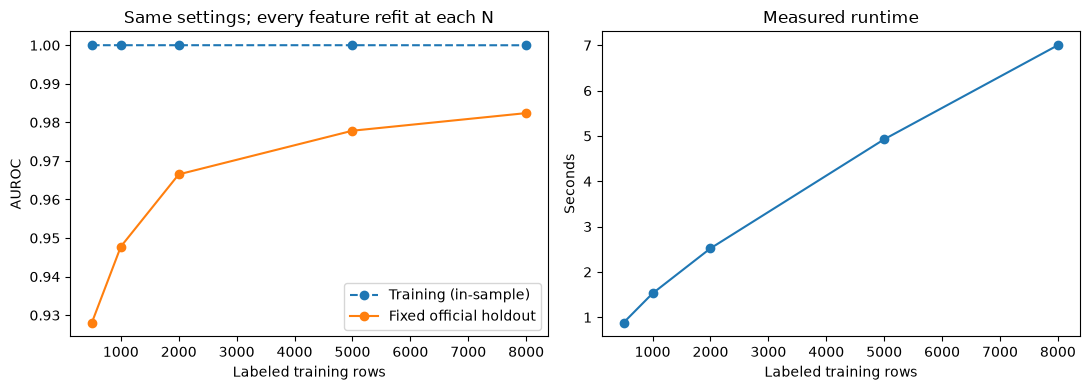

,training_rows,train_auc_in_sample,holdout_auc,runtime_s,vocabulary
0,500,1.000000,0.928074,0.882213,7727
1,1000,1.000000,0.947785,1.526738,15025
2,2000,1.000000,0.966512,2.520475,28335
3,5000,1.000000,0.977831,4.926052,50000
4,8000,0.999986,0.982396,7.001518,50000


In [17]:
# Fixed economical supervised learning-curve configuration, not a changing final-model search.
curve_lr=copy.deepcopy(BASE_SPECS['B0_word_lr'])
curve_dense=dense_spec(word_lm=False,info=False,genre=False)
curve_dense['params']=copy.deepcopy(base0['models']['model_d']['params'])
curve_rows=[];rng=np.random.default_rng(SEED)
class_indices=[rng.permutation(np.flatnonzero(development.label.to_numpy()==label)) for label in [0,1]]
sizes=[s for s in cfg['final_fit']['learning_sizes'] if s<=len(development)]
if MODE=='smoke':sizes=[len(development)//2,len(development)]
for size in sizes:
    start=time.time();indices=np.r_[class_indices[0][:size//2],class_indices[1][:size-size//2]]
    subset=development.iloc[indices].reset_index(drop=True)
    a,b=sparse_matrices(subset,official_holdout,curve_lr)
    lr=LogisticRegression(**curve_lr['params'],random_state=SEED,solver=cfg['models']['lr_solver']).fit(a,subset.label)
    ref=ReferenceFeatures(canonical=False,genre=False,info=False).fit(subset)
    da,db=ref.transform(subset),ref.transform(official_holdout)
    tree=fit_dense_estimator('lgb',curve_dense['params'],SEED).fit(da,subset.label)
    # Fixed mixture at every N; model parameters, feature definitions and holdout unchanged.
    w_lr,w_tree=cfg['final_fit']['learning_curve_weights']
    p_train=w_lr*lr.predict_proba(a)[:,1]+w_tree*tree.predict_proba(da)[:,1]
    p_val=w_lr*lr.predict_proba(b)[:,1]+w_tree*tree.predict_proba(db)[:,1]
    curve_rows.append({'training_rows':len(subset),'train_auc_in_sample':roc_auc_score(subset.label,p_train),'holdout_auc':roc_auc_score(official_holdout.label,p_val),'runtime_s':time.time()-start,'vocabulary':a.shape[1]})
    progress(f'Fixed-setting learning curve N={size}: holdout {curve_rows[-1]["holdout_auc"]:.5f}')
curve_table=pd.DataFrame(curve_rows);curve_table.to_csv(ART/'learning_curve.csv',index=False)
save_json('learning_curve_configuration.json',{'lr':curve_lr,'dense':curve_dense,'weights':cfg['final_fit']['learning_curve_weights'],'nested_subsets':True,'pseudo_labels':False})
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(curve_table.training_rows,curve_table.train_auc_in_sample,'o--',label='Training (in-sample)')
axes[0].plot(curve_table.training_rows,curve_table.holdout_auc,'o-',label='Fixed official holdout')
axes[0].set(xlabel='Labeled training rows',ylabel='AUROC',title='Same settings; every feature refit at each N');axes[0].legend()
axes[1].plot(curve_table.training_rows,curve_table.runtime_s,'o-');axes[1].set(xlabel='Labeled training rows',ylabel='Seconds',title='Measured runtime')
fig.tight_layout();fig.savefig(ART/'learning_curve.png',dpi=160);plt.show()
display(curve_table)


## Full-data refit and final CSV
The selected procedure is now retrained using all true labels. The model choice is frozen; the holdout is used for training only at this final stage. Unlabeled data is used only if its controlled student passed the declared checks.

In [18]:
if MODE=='full':
    frozen_test=test[['id','text']].copy()
    final_teacher=selected_predict(train_all,frozen_test,SEED,external=False)
    final_probability=final_teacher.copy()
    if SSL_SELECTED['enabled']:
        prepared=ssl_prepare(train_all,frozen_test,unlabeled,SEED,external=False,known_teacher_target=final_teacher)
        student,selections=ssl_student(prepared,**SSL_SELECTED['setting'])
        final_probability=(1-SSL_SELECTED['contribution'])*final_teacher+SSL_SELECTED['contribution']*student
        selections.to_csv(ART/'final_pseudo_labels.csv',index=False)
    result=pd.DataFrame({'id':test.id,'probability':final_probability})
    submission=sample[['id']].merge(result,on='id',how='left',validate='one_to_one')
    target_columns=[c for c in sample.columns if c!='id'];assert len(target_columns)==1
    submission=submission.rename(columns={'probability':target_columns[0]})[sample.columns]
    assert submission.id.equals(sample.id) and len(submission)==len(test) and submission.id.is_unique
    assert not submission.isna().any().any()
    values=submission[target_columns[0]].to_numpy()
    assert np.isfinite(values).all() and (values>=0).all() and (values<=1).all() and np.ptp(values)>0
    submission.to_csv(local_path(cfg['outputs']['submission']),index=False,float_format='%.17g')
    submission.to_csv(local_path(cfg['outputs']['conventional']),index=False,float_format='%.17g')
    pd.DataFrame({'id':test.id,'teacher':final_teacher,'final':final_probability}).to_csv(ART/'final_test_predictions.csv',index=False,float_format='%.17g')
    # Independent representative CPU refit; bypass prediction caches.
    representative=copy.deepcopy(BASE_SPECS['v2_lgb_pure'])
    ti,vi=CV_FOLDS[0];t=development.iloc[ti[:min(len(ti),1000)]];v=development.iloc[vi[:100]]
    p,_=fit_predict(t,v,representative,SEED,use_cache=False)
    q,_=fit_predict(t,v,representative,SEED,use_cache=False)
    np.testing.assert_allclose(p,q,atol=cfg['final_fit']['reproducibility_tolerance'],rtol=0)
    summary={'official_holdout':metrics(official_holdout.label,holdout_original),'supervised_nested_weight_development':metrics(development.label,outer_predictions['original']),'ssl_selection_cv':dict(best_ssl),'selected':SELECTED,'ssl':SSL_SELECTED,'rows':len(submission),'submission_sha256':hashlib.sha256(local_path(cfg['outputs']['submission']).read_bytes()).hexdigest(),'runtime_minutes':(time.time()-RUN_STARTED)/60,'config_hash':CONFIG_HASH,'implementation_hash':IMPLEMENTATION_HASH,'kaggle_public_auc':None,'kaggle_private_auc':None,'reproducibility_max_abs_delta':float(np.max(np.abs(p-q))),'test_fitting':False,'pretrained_models':False}
    save_json('run_summary.json',summary)
    display(submission.head());print('Validated final CSV:',local_path(cfg['outputs']['submission']))
    display(Markdown(f"**Measured final holdout AUROC: {summary['official_holdout']['auc']:.6f}.** Supervised nested-weight development AUROC (post model search): {summary['supervised_nested_weight_development']['auc']:.6f}. Runtime: {summary['runtime_minutes']:.1f} minutes. Kaggle scores are unknown until an actual submission is evaluated."))
else:
    print('Smoke mode complete: final CSV outputs intentionally not written.')
progress('Notebook execution finished successfully.')


,id,label
0,13001,0.995866
1,13002,0.023098
2,13003,0.201934
3,13004,0.027647
4,13005,0.996237


Validated final CSV: C:\Users\plum\Documents\Cornell Tech\human-or-ai-submissions\submissions\team-35\plum\submission_final_model_improvements.csv


**Measured final holdout AUROC: 0.999449.** Supervised nested-weight development AUROC (post model search): 0.997947. Runtime: 56.2 minutes. Kaggle scores are unknown until an actual submission is evaluated.

[56.2 min] Notebook execution finished successfully.


## Interpretation, reproducibility and AI assistance

The executed tables above are the evidence for the report: baseline/model selection and tuning (Q1), fixed-setting learning curve (Q2), controlled unlabeled experiment (Q3), held-out groups and actual FP/FN examples (Q4), feature/model/augmentation ablations (Q5), and configuration, environment and run manifest (Q6). `artifacts/final_model_improvements/` stores CSV/JSON outputs and fitting provenance. Near-duplicate purging is a separate sensitivity check; regex groups are imperfect and training poetry support is insufficient for a reliable poetry benchmark.

Keep selection scores, outer development scores and the frozen official holdout distinct. The official holdout was already inspected in older work, so it is not a pristine project-wide test set. No observed score establishes performance on hidden generators or private Kaggle examples. A rejected augmentation, feature block or SSL student is a valid negative result. The notebook preserves the corrected incumbent when promotion criteria are not met.

AI assistance: Codex reviewed the supplied notebooks and assignment, wrote this notebook and its configurations, added leakage/reproducibility checks, and executed the experiments. Measurements must come from successful execution rather than generated narrative. No hidden labels, external prediction APIs, pretrained weights or extra labeled corpora were used. User review and an actual Kaggle submission remain separate from local verification.

Primary references: [scikit-learn leakage practices](https://scikit-learn.org/stable/common_pitfalls.html), [NB-weighted linear text classifiers (Wang & Manning)](https://aclanthology.org/P12-2018/), [LightGBM bagging parameters](https://lightgbm.readthedocs.io/en/stable/Parameters.html#bagging_freq), and [scikit-learn calibration](https://scikit-learn.org/stable/modules/calibration.html).

## Recorded execution: result and observed limits

This run selected **the corrected v3 nine-specialist supervised ensemble**. The compact alternative's mean development-task change was -0.000034, so it did not pass the predeclared promotion threshold. The character-LM feature block improved the pure LightGBM branch from 0.982107 to 0.984374 pooled development AUROC, but that did not establish a better complete ensemble. The best SSL blend used student weight zero; pseudo-labeling is disabled in final fitting.

The frozen 2,000-row holdout scored **0.999449 AUROC**, versus 0.975318 after whitespace/HTML normalization. Removing 12 development rows whose duplicate components overlapped the unchanged holdout gave 0.999531 AUROC. These results demonstrate strong performance on the supplied splits and substantial formatting sensitivity; they do not establish performance on hidden generators or the Kaggle private set. Kaggle scores have not been measured by this notebook.

The actual error table shows several recurring patterns. Human false positives include a disambiguation list (3660), album/song credits (4947, 4062), and a technical first-person account (9028): formal or repetitive human writing can resemble generated prose. False negatives include encyclopedic AI biographies/geography (1362, 1834), a casual lowercase first-person passage (4519), and a recipe ingredient list (5498): AI can imitate familiar human-source styles. These are hypotheses based on the displayed passages, not proven causal feature attributions. The sports-season passage (5079) was assigned Film/TV, and the biographical opening of 9298 was assigned Recipe, illustrating that the regex domains are noisy proxies.

All 3,000 test IDs were exported in template order with continuous probabilities. The CPU representative refit matched exactly (maximum absolute probability difference 0). No pretrained weights, external prediction APIs or test-data fitting were used. Model selection used development evidence; the final holdout was evaluated only after selection was frozen. The older project had inspected this same holdout, which remains a limitation.

The tables and CSV/JSON artifacts are the primary evidence. Fit times restored from caches describe the original computations; the run-summary wall time describes the successful verification execution with reusable caches. This is a recorded result for configuration `0c790fa7c7e8aebd44887927a8874f12` and must not be treated as a future run's score without execution.
